# Re-done DBO figures — high-chl events, sea-ice edge, day of retreat

Nothing streams here. Every figure reloads from a pickle that an earlier
notebook already wrote to `$HOME`, so this notebook needs no `earthaccess` login and no network.

| figure | source cell | needs |
|---|---|---|
| 1. High-chl event frequency (>P90) | `1_pull_data/02_modis-chlor-a-daily-ease2.ipynb` section 6b | `~/modis_ease2_products.pkl` (or the `chl_box_series.csv` fallback) |
| 2. Sea-ice edge (15% SIC), decades + 2012 + current year | `1_pull_data/07_sea-ice-ssmi-and-nsidc0747.ipynb` (ice-edge cell) | `~/dbo_edge_maps.pkl` |
| 3. Sea-ice day of retreat per box | `1_pull_data/07_sea-ice-ssmi-and-nsidc0747.ipynb` section 4 | `~/nsidc0747_retreat_products.pkl` |

### What changed versus the originals

**Fig 1** — panel name is now the title; the trend and p-value moved *inside* the axes (orange when
significant); `p<0.001` instead of `8.45e-05`; y ticks on a fixed 5-unit step with the limit rounded
up to the next multiple of 5; x labels on every row; all fonts enlarged.

**Fig 2** — the red/green ramp is gone. Decades are a single-hue blue sequential ramp, 2012 is black
and the current year is Okabe–Ito vermillion, which stay distinguishable under deuteranopia,
protanopia and tritanopia. The spurious closed contour above DBO7 is removed by **despeckling**
before contouring: ice blobs and open-water holes smaller than `MIN_BLOB_KM2` are dissolved into
their surroundings, so only coherent edges survive. Legend now reads the bare year (e.g. `2025`)
rather than "this year so far", and the legend type is much larger.

**Fig 3** — much larger axis labels, tick labels, per-panel titles, suptitle and significance text;
the series legend moved out of panel *a* to a figure-level legend so it no longer competes with the
data.

Figures are written to `~/dbo_figs_redo/` as PNG (300 dpi) and PDF.

## 0. Imports, style and shared configuration

In [3]:
# === re-do-figs: imports, house style, grid + boxes, trend helpers ========================
import warnings, pickle, string
from pathlib import Path

import numpy as np, pandas as pd, xarray as xr
import matplotlib as mpl, matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.ticker import MultipleLocator
from matplotlib.path import Path as MplPath
from matplotlib.lines import Line2D
import cartopy.crs as ccrs, cartopy.feature as cfeature
from pyresample import AreaDefinition
from scipy.ndimage import gaussian_filter, label as _cc_label
from scipy.stats import theilslopes, kendalltau, norm
warnings.filterwarnings("ignore")

OUTDIR = Path.home() / "dbo_figs_redo"  # add your path
OUTDIR.mkdir(exist_ok=True)

mpl.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "figure.facecolor": "white",
    "savefig.bbox": "tight", "savefig.facecolor": "white",
    "font.family": "sans-serif",
    # DejaVu Sans pinned first so every figure renders identically on every machine.
    # Where no Helvetica/Arial exists matplotlib falls through to DejaVu Sans anyway,
    # so this just stops a local run from silently switching face. It also fixes bold: on macOS
    # the Helveticas are .ttc collections and matplotlib registers only face 0, so they are known
    # at weight 400 ONLY and fontweight="bold" against them renders REGULAR.
    "font.sans-serif": ["DejaVu Sans", "Arial", "Helvetica", "Nimbus Sans"],
    "axes.linewidth": 0.9, "axes.edgecolor": "0.2",
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.direction": "out", "ytick.direction": "out",
    "xtick.color": "0.2", "ytick.color": "0.2",
    "legend.frameon": False, "lines.solid_capstyle": "round",
})

# Okabe-Ito colorblind-safe categorical set (never cycled; picked by name)
OI = {"blue": "#0072B2", "green": "#009E73", "orange": "#D55E00", "purple": "#CC79A7",
      "sky": "#56B4E9", "amber": "#E69F00", "yellow": "#F0E442", "ink": "#222222"}
ACCENT, TRENDLINE = OI["blue"], OI["orange"]

# --- EASE-Grid 2.0 North, DBO 4 km subset: identical to every source notebook -------------
dbo_area = AreaDefinition(
    area_id="ease2_north_dbo_4km",
    description="EASE-Grid 2.0 North subset: Aleutians -> Beaufort (DBO1-8), 4 km",
    proj_id="EPSG:6931",
    projection={"proj": "laea", "lat_0": 90, "lon_0": 0, "x_0": 0, "y_0": 0,
                "datum": "WGS84", "units": "m"},
    width=906, height=845, area_extent=(-3_624_000, 992_000, 0, 4_372_000))
ny, nx = dbo_area.shape
x0, y0, x1, y1 = dbo_area.area_extent

DBO_BOXES = {
    "DBO1": [(63.769462,-172.312422),(61.945988,-172.186927),(61.846516,-175.790978),(63.662718,-176.147111)],
    "DBO2": [(65.107747,-170.865176),(65.097001,-167.859549),(64.481828,-167.907758),(64.493658,-170.840669)],
    "DBO3": [(66.785880,-171.330008),(68.608869,-171.419334),(68.572412,-166.481029),(66.752281,-166.755808)],
    "DBO4": [(71.994000,-164.226000),(71.801000,-159.729000),(70.641000,-160.305000),(70.821000,-164.556000)],
    "DBO5": [(71.807730,-158.537691),(71.635583,-155.931220),(71.110941,-156.307277),(71.278277,-158.847920)],
    "DBO6": [(71.850000,-150.108000),(70.890000,-150.976000),(71.159000,-153.865000),(72.119000,-152.980000)],
    "DBO7": [(70.868000,-141.528000),(69.946000,-142.679000),(70.333000,-145.439000),(71.253000,-144.256000)],
    "DBO8": [(70.834000,-125.155000),(70.049000,-126.997000),(70.664000,-129.354000),(71.442000,-127.431000)],
}
data_crs = ccrs.LambertAzimuthalEqualArea(central_latitude=90, central_longitude=0)
disp     = ccrs.LambertAzimuthalEqualArea(central_latitude=90, central_longitude=-152)

# --- Theil-Sen slope + AR(1)-adjusted Mann-Kendall p (same estimator as the source cells) --
def _lag1(x):
    x = np.asarray(x, float); a, b = x[1:], x[:-1]
    v = np.isfinite(a) & np.isfinite(b)
    return float(np.corrcoef(a[v], b[v])[0, 1]) if v.sum() >= 5 else 0.0

def mk_ar1(x, y, minn=8):
    x = np.asarray(x, float); y = np.asarray(y, float)
    v = np.isfinite(x) & np.isfinite(y); x, y = x[v], y[v]; n = len(x)
    nan = dict(slope=np.nan, intercept=np.nan, per_dec=np.nan, tau=np.nan,
               p_naive=np.nan, p_adj=np.nan, n=n)
    if n < minn:
        return nan
    slope, intercept, _, _ = theilslopes(y, x)
    tau, p_naive = kendalltau(x, y)
    sl, ic = np.polyfit(x, y, 1)
    phi = _lag1(y - (sl * x + ic))                      # AR(1) of the detrended residual
    n_eff = n * (1 - phi) / (1 + phi) if (abs(phi) < 1 and phi != 0) else n
    p_adj = (2 * (1 - norm.cdf(abs(tau / np.sqrt(2 * (2*n_eff + 5) / (9*n_eff*(n_eff - 1))))))
             if n_eff > 4 else np.nan)
    return dict(slope=slope, intercept=intercept, per_dec=slope*10, tau=tau,
                p_naive=p_naive, p_adj=p_adj, n=n)

def _stars(p):
    return ("***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else "ns") \
        if np.isfinite(p) else "n/a"

def _pfmt(p):
    """Readable p: '<0.001' rather than 8.45e-05."""
    if not np.isfinite(p):    return "p=n/a"
    if p < 0.001:             return "p<0.001"
    return f"p={p:.3f}"

def save_fig(fig, stem):
    for ext in ("png", "pdf"):
        fig.savefig(OUTDIR / f"{stem}.{ext}")
    print(f"saved -> {OUTDIR/stem}.png  and  .pdf")

print("setup OK |", OUTDIR)

setup OK | ~/dbo_figs_redo


In [4]:
# === DBO box masks on the EASE-2 grid (needed by figures 2 and 3) ========================
lons2d, lats2d = dbo_area.get_lonlats()
grid_pts = np.column_stack([lons2d.ravel(), lats2d.ravel()])
box_masks = {name: MplPath([(lo, la) for la, lo in corners] + [(corners[0][1], corners[0][0])])
                        .contains_points(grid_pts).reshape(lons2d.shape)
             for name, corners in DBO_BOXES.items()}
for name, m in box_masks.items():
    print(f"  {name}: {int(m.sum()):>6,} grid cells")

  DBO1:  2,412 grid cells
  DBO2:    605 grid cells
  DBO3:  2,561 grid cells
  DBO4:  1,293 grid cells
  DBO5:    351 grid cells
  DBO6:    739 grid cells
  DBO7:    773 grid cells
  DBO8:    760 grid cells


## 1. High-chl event frequency (> P90), REGION + DBO1–8

Rebuilt from `02_modis-chlor-a-daily-ease2.ipynb` cell 43. A **high-chl event day** is a day whose
box-mean chlorophyll exceeds that box's own record P90; the bars count event days per year, and the
trend is Theil–Sen with an AR(1)-adjusted Mann–Kendall p.

### Which chl product

The published numbers use `box_ts` — **standard `chlor_a`** from the MODIS L3m stream. The CSV
fallback (`scorecard/box_series/chl_box_series.csv`) is **AO.emp** (Lewis & Arrigo), a different
product, and it shifts the trends (e.g. DBO2 reads +4.0 events/dec there vs +3.45 from `chlor_a`).
The cell below prefers, in order: `box_ts` already in memory → the pickle → the CSV, and prints
which one it used. If it lands on the CSV, the figure is AO.emp and should be labelled as such.

In [3]:
# === Load the daily per-box chl series (no streaming) ====================================
CHL_VAR   = "daily_mean"
CHL_PKLS  = [Path.home() / "modis_ease2_products.pkl",  # add your path
             Path.home() / "modis_ease2_dbo_products.pkl",  # add your path
             Path.home() / "modis_chl_products.pkl"]  # add your path
CSV_CANDS = [p / "scorecard/box_series/chl_box_series.csv"
             for p in (Path.home()/"ADD_YOUR_PATH", Path.cwd(), Path.cwd().parent,  # add your path
                       Path.home()/"shared/<project folder>")]  # add your path

def _to_frame(bts, var=CHL_VAR):
    """{box: <holder>} -> DataFrame(date x box).

    modis-single-projection stores box_ts[name] as a PLAIN DICT
    {"daily_mean": DataArray, "daily_median": DataArray} — not an xr.Dataset — so test by
    subscripting for the key rather than sniffing for .data_vars.
    """
    cols = {}
    for n, obj in bts.items():
        try:
            da = obj[var]                       # plain dict, xr.Dataset, or DataFrame column
        except (KeyError, IndexError, TypeError):
            da = obj                            # already the DataArray / Series itself
        if hasattr(da, "coords") and "time" in da.coords:
            t = pd.to_datetime(np.asarray(da["time"].values))
        elif hasattr(da, "index"):
            t = pd.to_datetime(np.asarray(da.index))
        else:
            raise TypeError(f"{n}: no time axis on {type(da).__name__} "
                            f"(box_ts[{n!r}] is a {type(obj).__name__})")
        cols[n] = pd.Series(np.asarray(da.values, float), index=t)
    return pd.DataFrame(cols).sort_index()

CHL, CHL_SOURCE, CHL_PRODUCT = None, None, None
if "box_ts" in globals() and isinstance(globals()["box_ts"], dict) and box_ts:
    CHL = _to_frame(box_ts); CHL_SOURCE = "box_ts already in memory"; CHL_PRODUCT = "chlor_a"
if CHL is None:
    for p in CHL_PKLS:
        if p.exists():
            _d = pickle.load(open(p, "rb"))
            CHL = _to_frame(_d["box_ts"]); CHL_SOURCE = p.name; CHL_PRODUCT = "chlor_a"
            break
if CHL is None:
    for p in CSV_CANDS:
        if p.exists():
            CHL = pd.read_csv(p, parse_dates=["date"]).set_index("date").sort_index()
            CHL_SOURCE = str(p); CHL_PRODUCT = "AO.emp"
            print("!! FALLBACK: this CSV is AO.emp, NOT standard chlor_a — the trends will differ\n"
                  "   from the published panel (DBO2 reads +4.0 events/dec here vs +3.45 for chlor_a).")
            break
if CHL is None:
    raise FileNotFoundError(
        "No chl source found. Expected one of:\n  " + "\n  ".join(str(p) for p in CHL_PKLS) +
        "\nor scorecard/box_series/chl_box_series.csv. Run 02_modis-chlor-a-daily-ease2.ipynb "
        "section 6b once to write ~/modis_ease2_products.pkl.")

CHL = CHL[[c for c in DBO_BOXES if c in CHL.columns]]
print(f"chl source : {CHL_SOURCE}  ({CHL_PRODUCT})")
print(f"shape      : {CHL.shape[0]:,} days x {CHL.shape[1]} boxes  |  "
      f"{CHL.index.min().date()} -> {CHL.index.max().date()}")

chl source : modis_ease2_products.pkl  (chlor_a)
shape      : 8,530 days x 8 boxes  |  2002-07-04 -> 2025-11-30


Mann-Kendall on annual high-chl event count (Theil-Sen slope, AR(1)-adjusted p) | product = chlor_a

         P90  trend(events/dec)    tau  p_MK_naive  p_MK_AR1 sig
series                                                          
REGION 2.431              5.714  0.320       0.030     0.020   *
DBO1   1.731              5.000  0.452       0.002     0.060  ns
DBO2   4.354              3.452  0.356       0.017     0.039   *
DBO3   2.955              3.229  0.314       0.036     0.006  **
DBO4   1.730              0.000 -0.053       0.726     0.729  ns
DBO5   2.480              0.000  0.091       0.547     0.487  ns
DBO6   3.730              0.000  0.074       0.630     0.566  ns
DBO7   3.272              0.000  0.023       0.881     0.792  ns
DBO8   2.750              1.144  0.108       0.469     0.428  ns
saved -> ~/dbo_figs_redo/fig1_high_chl_events.png  and  .pdf


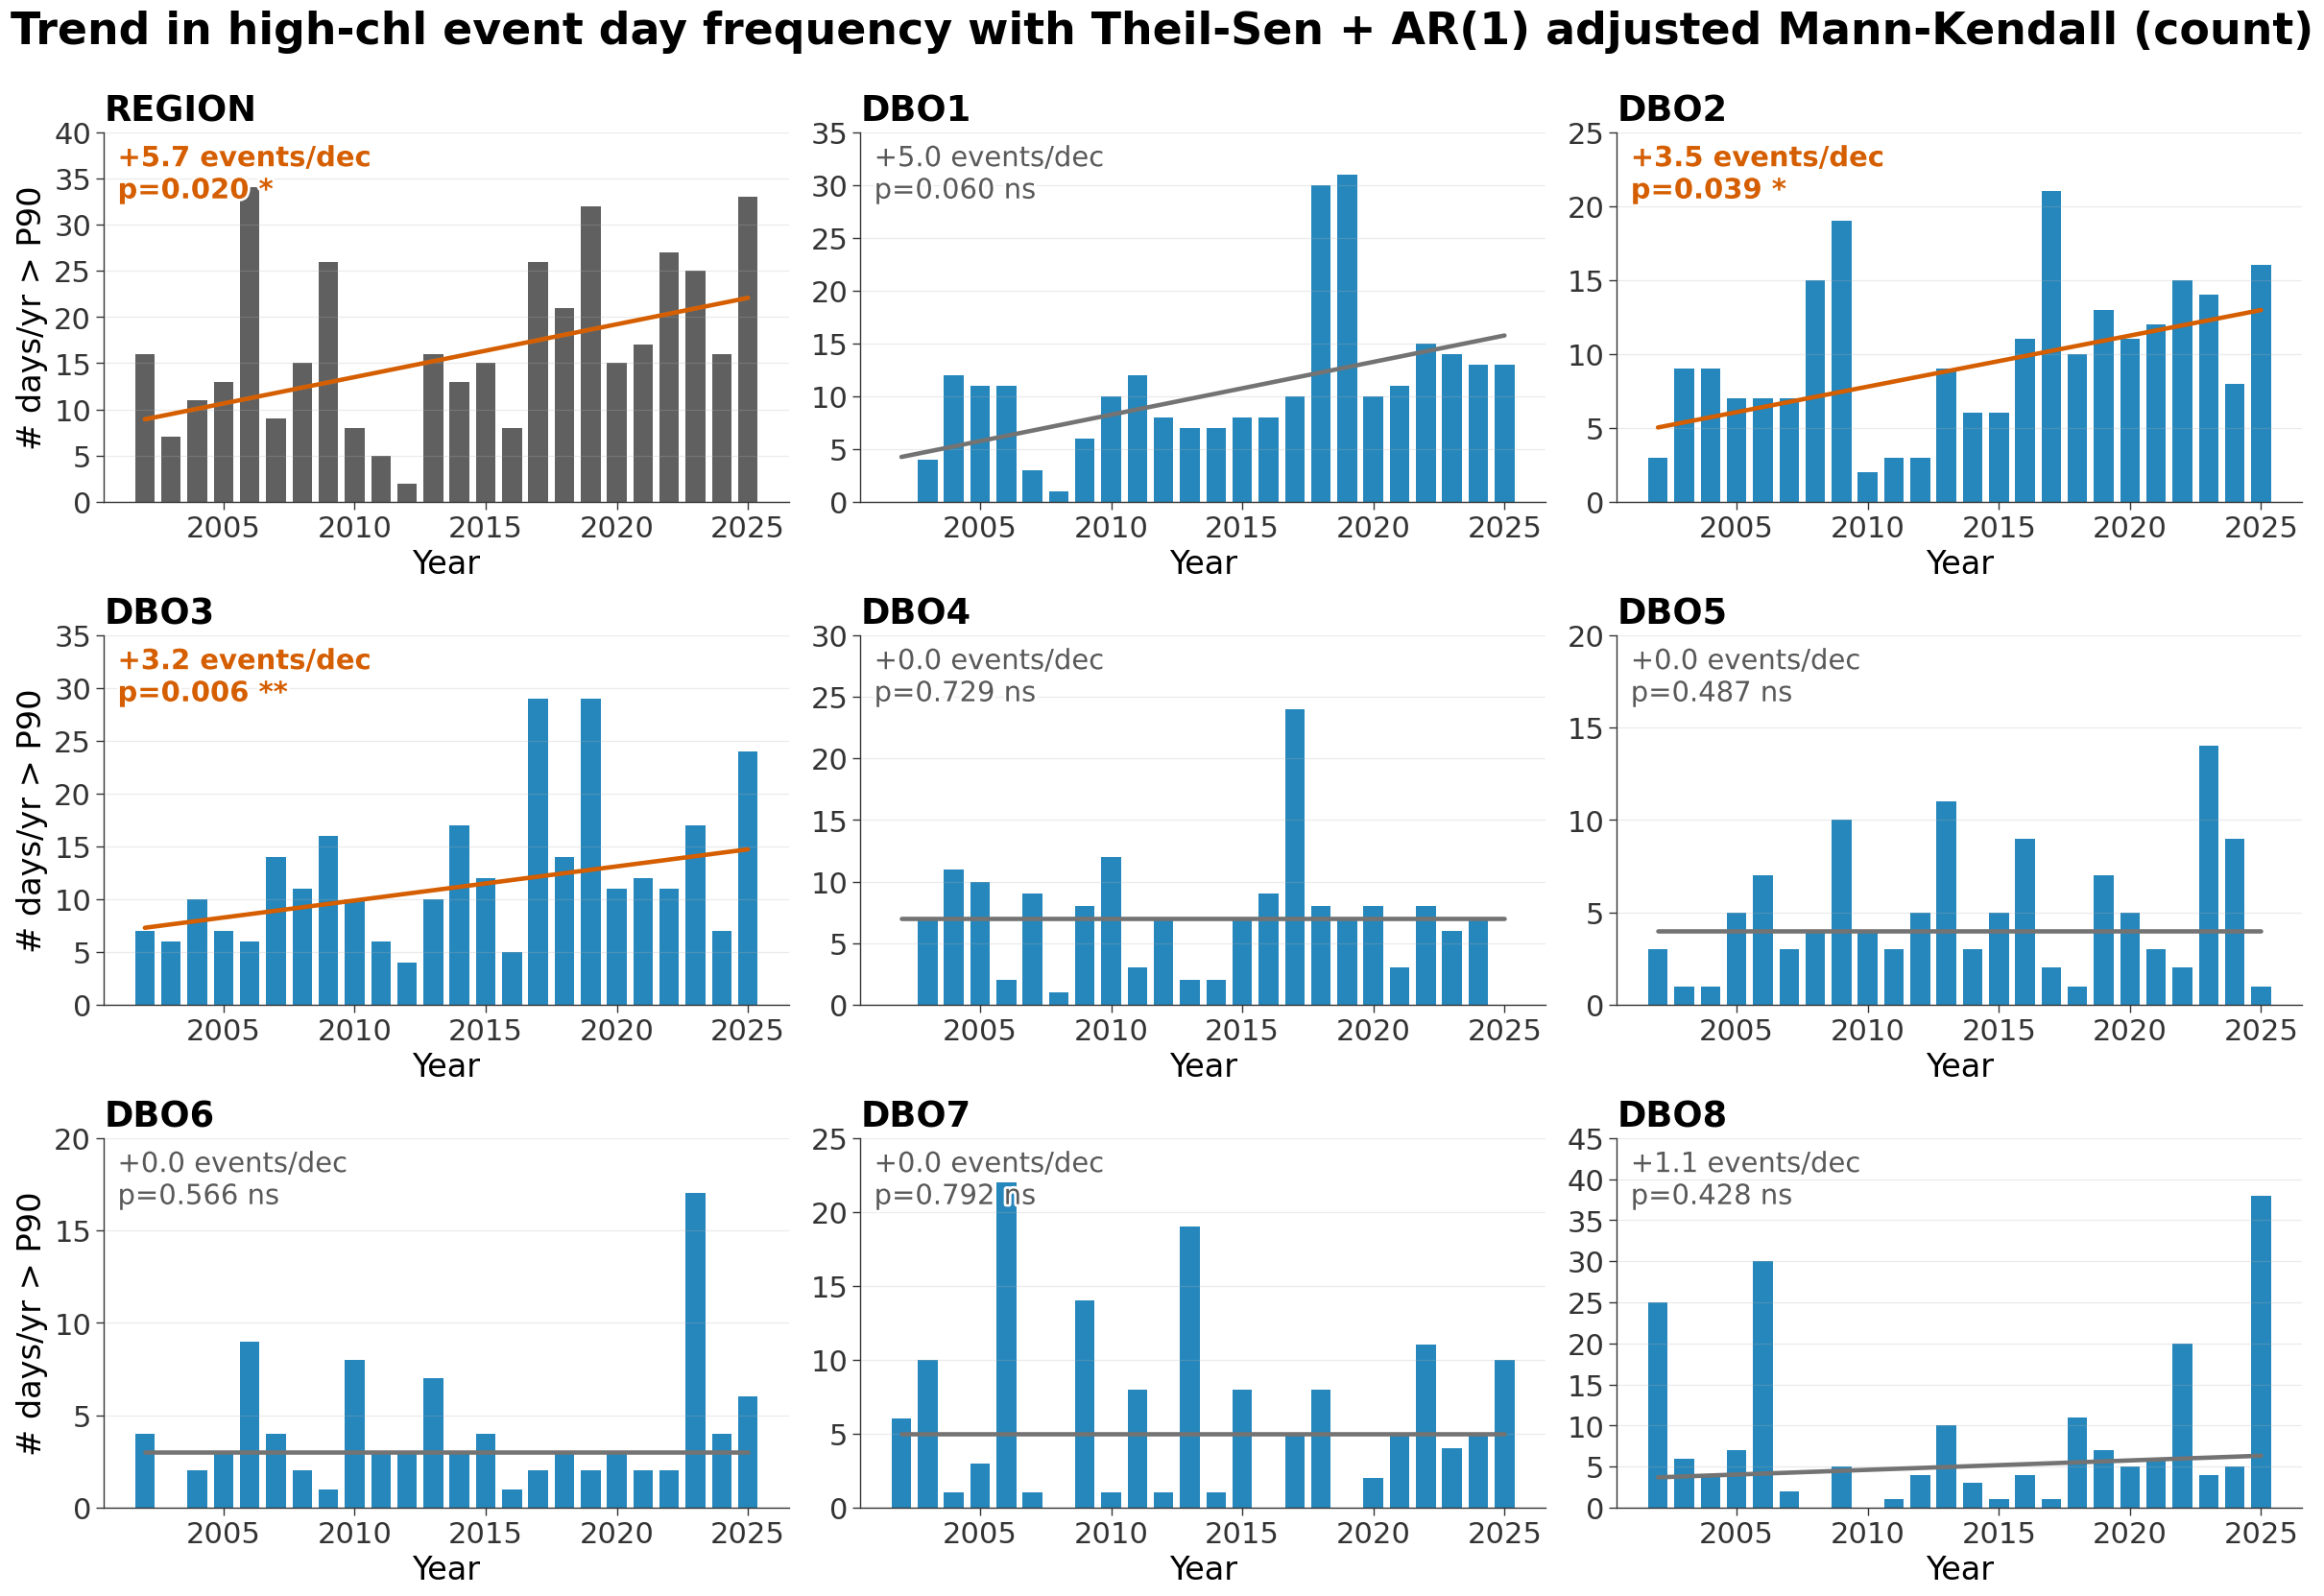

In [7]:
# === FIGURE 1 — trend in high-chl (>P90) event frequency, REGION + DBO1-8 ================
PCTL   = 90
METRIC = "count"        # "count" = event-days/yr | "frac" = % of valid days/yr
FS_SUP, FS_TITLE, FS_LAB, FS_TICK, FS_STAT = 30, 24, 22, 20, 19

names = list(CHL.columns)
time  = CHL.index
M = CHL.to_numpy(float)
M[~np.isfinite(M) | (M <= 0)] = np.nan          # chl <= 0 is a retrieval failure, not a low value

def annual_events(series, t):
    ok = np.isfinite(series); s, tt = series[ok], t[ok]
    p90 = np.nanpercentile(s, PCTL)
    by  = pd.Series(s > p90, index=tt.year.values).groupby(level=0)
    out = by.sum() if METRIC == "count" else 100 * by.mean()
    return p90, out.index.values.astype(float), out.values.astype(float)

series_all = {"REGION": np.nanmean(M, axis=1), **{n: M[:, j] for j, n in enumerate(names)}}

rows, results = [], {}
for key, s in series_all.items():
    p90, yrs, vals = annual_events(s, time)
    r = mk_ar1(yrs, vals); r.update(p90=p90, yrs=yrs, vals=vals); results[key] = r
    rows.append((key, p90, r["per_dec"], r["tau"], r["p_naive"], r["p_adj"], _stars(r["p_adj"])))

unit = "events/dec" if METRIC == "count" else "%pts/dec"
tbl1 = pd.DataFrame(rows, columns=["series", f"P{PCTL}", f"trend({unit})", "tau",
                                   "p_MK_naive", "p_MK_AR1", "sig"]).set_index("series")
pd.set_option("display.float_format", lambda v: f"{v:.3f}")
print(f"Mann-Kendall on annual high-chl event {METRIC} "
      f"(Theil-Sen slope, AR(1)-adjusted p) | product = {CHL_PRODUCT}\n")
print(tbl1)

keys = list(series_all)
fig, axes = plt.subplots(3, 3, figsize=(22, 15), sharex=True)
axes = axes.ravel()
for ax, key in zip(axes, keys):
    r = results[key]
    ax.bar(r["yrs"], r["vals"], color=("#444444" if key == "REGION" else ACCENT),
           alpha=0.85, width=0.75)
    sig = np.isfinite(r["p_adj"]) and r["p_adj"] < 0.05
    if np.isfinite(r["slope"]):
        ax.plot(r["yrs"], r["intercept"] + r["slope"] * r["yrs"], "-",
                color=(TRENDLINE if sig else "0.45"), lw=3.0, zorder=3)

    # panel name is the title; the statistic lives inside the axes, orange when significant
    ax.set_title(key, fontsize=FS_TITLE, loc="left", fontweight="bold", pad=8)
    ax.text(0.02, 0.965,
            f"{r['per_dec']:+.1f} {unit}\n{_pfmt(r['p_adj'])} {_stars(r['p_adj'])}",
            transform=ax.transAxes, ha="left", va="top", fontsize=FS_STAT,
            color=(TRENDLINE if sig else "0.35"), fontweight=("bold" if sig else "normal"),
            linespacing=1.25,
            path_effects=[pe.withStroke(linewidth=3.5, foreground="white")], zorder=6)

    # y axis: fixed 5-unit ticks, limit rounded up to the next multiple of 5, with ~12%
    # headroom so the tallest bar never collides with the statistic in the top-left corner
    top = max(5.0, 5.0 * np.ceil(np.nanmax(r["vals"]) * 1.12 / 5.0))
    ax.set_ylim(0, top)
    ax.yaxis.set_major_locator(MultipleLocator(5))
    ax.tick_params(axis="both", labelsize=FS_TICK, length=5, width=0.9, labelbottom=True)
    ax.grid(alpha=0.25, axis="y")
    for sp in ("top", "right"):
        ax.spines[sp].set_visible(False)

for ax in axes[len(keys):]:
    ax.axis("off")
ylab = f"# days/yr > P{PCTL}" if METRIC == "count" else f"% valid days > P{PCTL}"
for ax in axes[::3]:
    ax.set_ylabel(ylab, fontsize=FS_LAB)
for ax in axes:
    ax.set_xlabel("Year", fontsize=FS_LAB)      # x label on every row, not just the bottom
fig.suptitle(f"Trend in high-chl event day frequency with Theil-Sen + AR(1) adjusted Mann-Kendall ({METRIC})",
             fontsize=FS_SUP, y=1.005, fontweight="bold")
plt.tight_layout()
save_fig(fig, "fig1_high_chl_events")
plt.show()

## 2. DBO sea-ice edge (15% SIC) — decadal means + 2012 and the current year

Rebuilt from `1_pull_data/07_sea-ice-ssmi-and-nsidc0747.ipynb` (ice-edge cell), reloading the composites from `~/dbo_edge_maps.pkl`
(no streaming, no `granules_by_day`).

**Colorblind-safe palette.** Decades are a single-hue blue sequential ramp — ordered lightness
carries the time axis even with no hue perception at all. The two reference years are black (2012)
and Okabe–Ito vermillion `#D55E00` (current year); the DBO boxes are neutral dark gray with a white
halo. No red-versus-green pair remains.

**Despeckling.** The stray closed contour above DBO7 was a handful of isolated grid cells sitting
just over 15% in the decadal composite. Before contouring, `_despeckle` labels the connected
components of the `SIC ≥ 15%` field, dissolves any ice blob smaller than `MIN_BLOB_KM2` down below
the threshold, and fills any open-water hole smaller than the same threshold back above it. Only
coherent ice edges survive. `MIN_BLOB_KM2` is printed with a per-map count of what it removed —
raise it if any speckle remains, lower it if a real small feature disappears.

In [8]:
# === Load the sea-ice edge composites (no streaming) =====================================
EDGE_CACHE = Path.home() / "dbo_edge_maps.pkl"  # add your path
if not EDGE_CACHE.exists():
    raise FileNotFoundError(
        f"{EDGE_CACHE} not found. Run `1_pull_data/07_sea-ice-ssmi-and-nsidc0747.ipynb` (ice-edge cell) once (it streams and "
        "then pickles dec_maps/ref_maps), or copy the pickle into $HOME.")

_c = pickle.load(open(EDGE_CACHE, "rb"))
dec_maps, ref_maps = _c["dec_maps"], _c["ref_maps"]

EDGE   = 15.0                                   # % SIC defining the ice edge
MONTHS = {"March": 3, "September": 9}           # winter max, summer min
CUR_YEAR = max(y for (y, _m) in ref_maps if y != 2012)
DECADES  = [(1980, 1989), (1990, 1999), (2000, 2009), (2010, 2019), (2020, CUR_YEAR)]

print(f"loaded {EDGE_CACHE.name} — no streaming")
print("  decadal composites:", sorted(dec_maps))
print("  reference-year composites:", sorted(ref_maps), f"| current year = {CUR_YEAR}")

loaded dbo_edge_maps.pkl — no streaming
  decadal composites: [(1980, 3), (1980, 9), (1990, 3), (1990, 9), (2000, 3), (2000, 9), (2010, 3), (2010, 9), (2020, 3), (2020, 9)]
  reference-year composites: [(2012, 3), (2012, 9), (2025, 3), (2025, 9)] | current year = 2025


static-value cells masked (land / lake flags, identical across all 14 composites): 117,603 = 1,881,648 km²
despeckling:
    1980s March: removed 1 ice speck(s), filled 7 water hole(s) (< 6,000 km2)
    1980s September: removed 1 ice speck(s), filled 7 water hole(s) (< 6,000 km2)
    1990s March: removed 1 ice speck(s), filled 7 water hole(s) (< 6,000 km2)
    1990s September: removed 9 ice speck(s), filled 8 water hole(s) (< 6,000 km2)
    2000s March: removed 1 ice speck(s), filled 7 water hole(s) (< 6,000 km2)
    2000s September: removed 8 ice speck(s), filled 7 water hole(s) (< 6,000 km2)
    2010s March: removed 1 ice speck(s), filled 7 water hole(s) (< 6,000 km2)
    2010s September: removed 1 ice speck(s), filled 7 water hole(s) (< 6,000 km2)
    2020s March: removed 1 ice speck(s), filled 7 water hole(s) (< 6,000 km2)
    2020s September: removed 1 ice speck(s), filled 7 water hole(s) (< 6,000 km2)
    2012 March: removed 1 ice speck(s), filled 8 water hole(s) (< 6,000 km2)
   

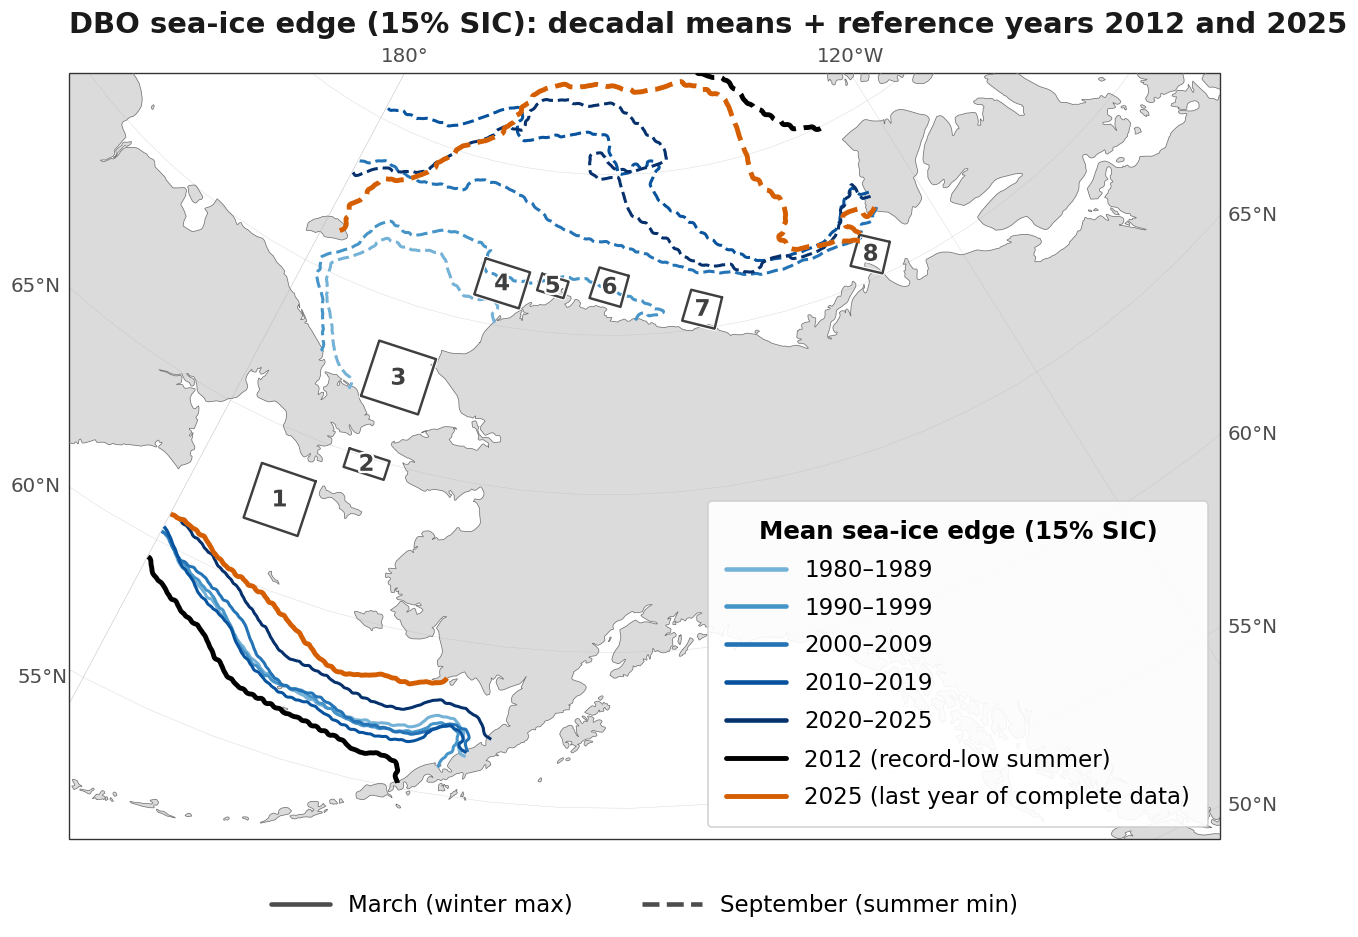


main-pack rule dissolved 208 component(s), 124 of them >= 1,000 km².  (The per-composite lines above are the separate, much smaller
  despeckle removals below 6,000 km²; those are not listed here.)
  Resolved features this figure does NOT draw. 'detached ice' is a real ice patch that
  is not part of the pack boundary — put anything large in the caption:
      area km²  composite          kind            centre
       169,616  1980s September    enclosed water  (70.33N,  -126.44E)
        94,272  1990s September    enclosed water  (70.32N,  -121.23E)
        62,336  1990s September    enclosed water  (69.93N,  -135.51E)
        27,472  1980s September    detached ice    (70.05N,  -117.93E)
        13,104  2025 September     detached ice    (69.64N,  -124.91E)
        12,688  1980s September    detached ice    (69.95N,  -127.70E)
        11,632  2000s September    detached ice    (69.09N,  -116.90E)
        11,632  2025 September     detached ice    (69.09N,  -116.90E)
        11,392  

In [9]:
# === FIGURE 2 — sea-ice edge map, CVD-safe palette + despeckled contours =================
# ---- tunables -------------------------------------------------------------------------
MAIN_PACK_ONLY = True      # <<< keep ONLY the boundary of the main ice body.
# A "mean sea-ice edge" is a boundary line across the domain. A detached closed loop is a separate
# patch of persistent ice, not an edge, so it does not belong on this figure at any size -- which is
# why this is a connectivity rule and not an area threshold. Every ice component that is not the
# largest is dissolved, and every pocket of open water not connected to the open ocean is filled, so
# each composite contributes exactly one boundary. Dropped components are listed by the audit print.
MIN_BLOB_KM2 = 6_000.0     # dissolve ice blobs / water holes smaller than this before contouring
SMOOTH_SIGMA = 1.5         # gaussian smoothing of the composite (same as the original cell)
FS_TITLE_M, FS_LEG, FS_LEGTITLE, FS_GRID, FS_BOXNUM = 19, 15, 16, 13, 15

CELL_KM2  = (4.0 * 4.0)                                  # EASE-2 4 km grid
MIN_CELLS = max(1, int(round(MIN_BLOB_KM2 / CELL_KM2)))

DEC_COLORS = plt.cm.Blues(np.linspace(0.48, 1.0, len(DECADES)))   # ordered, single hue
REF = [(2012,     "#000000",   "2012 (record-low summer)"),
       (CUR_YEAR, OI["orange"], f"{CUR_YEAR} (last year of complete data)")]
BOX_COLOR = "#3f3f3f"

# --- static-value mask: land / inland-lake flags ----------------------------------------
# Great Bear, Great Slave, Athabasca etc. carry a constant flag value that decodes below 15%,
# sitting inside land that decodes above it, so they draw a closed "ice edge" ring in EVERY
# composite. The giveaway is that they are bit-identical in all of them — real sea ice cannot be,
# not between March and September and not across 46 years. So drop cells that are finite in every
# composite AND never vary. This is what to fix, NOT MIN_BLOB_KM2: raising the threshold past a
# 36,000 km2 lake would also delete real sea-ice features of the same size.
_allmaps = np.stack([np.asarray(m, float) for m in
                     list(dec_maps.values()) + list(ref_maps.values())])
_finite_everywhere = np.isfinite(_allmaps).all(axis=0)
_span = np.nanmax(_allmaps, axis=0) - np.nanmin(_allmaps, axis=0)
STATIC = _finite_everywhere & (_span < 1e-6)
print(f"static-value cells masked (land / lake flags, identical across all "
      f"{_allmaps.shape[0]} composites): {int(STATIC.sum()):,} "
      f"= {STATIC.sum()*CELL_KM2:,.0f} km²")
del _allmaps, _span

REMOVED_LOG = []            # (composite, kind, km2, lat, lon) for everything dissolved
_CONN8 = np.ones((3, 3), int)   # 8-connectivity: a 1-cell diagonal pinch is still one pack

def _log_drop(lab, ids, kind, tag):
    for cid in ids:
        sel = np.argwhere(lab == cid)
        j, i = sel.mean(axis=0).astype(int)
        REMOVED_LOG.append((tag, kind, len(sel) * CELL_KM2, lats2d[j, i], lons2d[j, i]))

def _main_pack_only(a, tag=""):
    """Keep the boundary of the largest ice body only, and fill every enclosed water pocket."""
    fin = np.isfinite(a)
    ice = fin & (a >= EDGE)
    lab, n = _cc_label(ice, structure=_CONN8)
    if n > 1:
        sz = np.bincount(lab.ravel()); sz[0] = 0
        others = [c for c in np.flatnonzero(sz) if c != sz.argmax()]
        if others:
            _log_drop(lab, others, "detached ice", tag)
            a[np.isin(lab, others)] = EDGE - 5.0
    water = fin & (a < EDGE)
    lab, n = _cc_label(water, structure=_CONN8)
    if n > 1:
        sz = np.bincount(lab.ravel()); sz[0] = 0
        others = [c for c in np.flatnonzero(sz) if c != sz.argmax()]
        if others:
            _log_drop(lab, others, "enclosed water", tag)
            a[np.isin(lab, others)] = EDGE + 5.0
    return a

def _despeckle(a, min_cells=MIN_CELLS, verbose=False, tag=""):
    """Drop ice islands and fill open-water holes below min_cells, so isolated pixels
    just over the 15% threshold cannot draw a spurious closed contour."""
    a = np.array(a, float)
    a[STATIC] = np.nan                      # land / lake flags out before anything is contoured
    fin = np.isfinite(a)
    n_ice = n_hole = 0
    ice = fin & (a >= EDGE)
    lab, n = _cc_label(ice)
    if n:
        sz = np.bincount(lab.ravel()); sz[0] = 0
        bad = np.flatnonzero((sz > 0) & (sz < min_cells))
        if bad.size:
            drop = np.isin(lab, bad); n_ice = int(bad.size)
            a[drop] = EDGE - 5.0
    water = fin & (a < EDGE)
    lab, n = _cc_label(water)
    if n:
        sz = np.bincount(lab.ravel()); sz[0] = 0
        bad = np.flatnonzero((sz > 0) & (sz < min_cells))
        if bad.size:
            fill = np.isin(lab, bad); n_hole = int(bad.size)
            a[fill] = EDGE + 5.0
    if verbose and (n_ice or n_hole):
        print(f"    {tag}: removed {n_ice} ice speck(s), filled {n_hole} water hole(s) "
              f"(< {MIN_BLOB_KM2:,.0f} km2)")
    return a

def _smooth(a, sig=SMOOTH_SIGMA):
    v = np.isfinite(a).astype(float)
    a0 = np.where(np.isfinite(a), a, 0.0)
    den = gaussian_filter(v, sig)
    out = gaussian_filter(a0, sig) / np.where(den > 0, den, np.nan)
    out[v == 0] = np.nan
    return out

def _clean(a, tag=""):
    a = _despeckle(a, verbose=True, tag=tag)
    if MAIN_PACK_ONLY:
        a = _main_pack_only(a, tag=tag)
    return _smooth(a)

# ---- draw -----------------------------------------------------------------------------
X2, Y2 = np.meshgrid(*dbo_area.get_proj_vectors())
fig, ax = plt.subplots(figsize=(13.5, 11), subplot_kw={"projection": disp})
ax.set_extent([-180, -120, 54, 76], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND, facecolor="0.86", zorder=2)
ax.coastlines(lw=0.5, color="0.45", zorder=3)
gl = ax.gridlines(draw_labels=True, lw=0.3, color="0.7", alpha=0.5)
gl.xlabel_style = {"size": FS_GRID, "color": "0.3"}
gl.ylabel_style = {"size": FS_GRID, "color": "0.3"}

print("despeckling:")
for ci, (d0, d1) in enumerate(DECADES):
    for mo, ls in [("March", "-"), ("September", "--")]:
        em = dec_maps.get((d0, MONTHS[mo]))
        if em is None or np.isfinite(em).sum() < 10:
            continue
        ax.contour(X2, Y2, _clean(em, f"{d0}s {mo}"), levels=[EDGE], colors=[DEC_COLORS[ci]],
                   linewidths=2.0, linestyles=ls, transform=data_crs, zorder=4)
for y, color, lab in REF:
    drew = False
    for mo, ls in [("March", "-"), ("September", "--")]:
        em = ref_maps.get((y, MONTHS[mo]))
        if em is None or np.isfinite(em).sum() < 10:
            continue
        ax.contour(X2, Y2, _clean(em, f"{y} {mo}"), levels=[EDGE], colors=[color],
                   linewidths=3.2, linestyles=ls, transform=data_crs, zorder=6)
        drew = True
    if not drew:
        print(f"  note: no March/September edge available yet for {y}")

for name, corners in DBO_BOXES.items():
    ring = corners + [corners[0]]
    ax.plot([p[1] for p in ring], [p[0] for p in ring], transform=ccrs.PlateCarree(),
            color=BOX_COLOR, lw=1.6, zorder=5,
            path_effects=[pe.withStroke(linewidth=3.0, foreground="white")])
    cla = np.mean([c[0] for c in corners]); clo = np.mean([c[1] for c in corners])
    ax.text(clo, cla, name[-1], transform=ccrs.PlateCarree(), color=BOX_COLOR,
            fontsize=FS_BOXNUM, fontweight="bold", ha="center", va="center", zorder=7,
            path_effects=[pe.withStroke(linewidth=3.0, foreground="white")])

dec_handles = [Line2D([0], [0], color=DEC_COLORS[i], lw=3.0, label=f"{d0}–{d1}")
               for i, (d0, d1) in enumerate(DECADES)]
ref_handles = [Line2D([0], [0], color=c, lw=3.2, label=lab) for _, c, lab in REF]
sea_handles = [Line2D([0], [0], color="0.3", lw=3.0, ls="-",  label="March (winter max)"),
               Line2D([0], [0], color="0.3", lw=3.0, ls="--", label="September (summer min)")]
# The decade key sits inside on an opaque white panel so contours cannot show through it.
_legkw = dict(fontsize=FS_LEG, labelspacing=0.65, handlelength=2.6, borderpad=0.8,
              frameon=True, facecolor="white", edgecolor="0.8", framealpha=0.92)
leg1 = ax.legend(handles=dec_handles + ref_handles, title="Mean sea-ice edge (15% SIC)",
                 loc="lower right", title_fontsize=FS_LEGTITLE, **_legkw)
leg1.get_title().set_fontweight("bold")
leg1.set_zorder(10)
ax.add_artist(leg1)
# The season key goes OUTSIDE the axes, centred under the map. Every in-map corner has either
# March or September contours running through it at some point in the record, so anywhere inside
# risks covering data; below the axes it cannot, whatever the composites look like.
leg2 = ax.legend(handles=sea_handles, loc="upper center", bbox_to_anchor=(0.5, -0.045),
                 ncol=2, columnspacing=3.0, fontsize=FS_LEG, handlelength=2.6,
                 frameon=False)
# Title is an axes-anchored text, not ax.set_title: with gridline labels on, cartopy's
# _update_title_position sends a GeoAxes title to y=inf and it never renders.
ax.text(0.0, 1.045, f"DBO sea-ice edge (15% SIC): decadal means + reference years 2012 and {CUR_YEAR}",
        transform=ax.transAxes, ha="left", va="bottom",
        fontsize=FS_TITLE_M, fontweight="bold", color="0.1")
# NB: no plt.tight_layout() here either — on a cartopy GeoAxes it degenerates the axes boundary
# and the gridline labeller then raises GEOSException. rcParams savefig.bbox="tight" does the job.
save_fig(fig, "fig2_seaice_edge")
plt.show()

# ---- audit: what was dissolved, largest first ------------------------------------------
AUDIT_MIN_KM2 = 1_000.0
_big = sorted([r for r in REMOVED_LOG if r[2] >= AUDIT_MIN_KM2], key=lambda r: -r[2])
print(f"\nmain-pack rule dissolved {len(REMOVED_LOG):,} component(s), {len(_big)} of them "
      f">= {AUDIT_MIN_KM2:,.0f} km².  (The per-composite lines above are the separate, much "
      f"smaller\n  despeckle removals below {MIN_BLOB_KM2:,.0f} km²; those are not listed here.)")
if _big:
    print("  Resolved features this figure does NOT draw. 'detached ice' is a real ice patch that\n"
          "  is not part of the pack boundary — put anything large in the caption:")
    print(f"    {'area km²':>10}  {'composite':<18} {'kind':<15} centre")
    for tag, kind, km2, la, lo in _big:
        print(f"    {km2:10,.0f}  {tag:<18} {kind:<15} ({la:5.2f}N, {lo:8.2f}E)")

---

# Part B — wind, density, SST and salinity

Five more remade figures. These need the **cached monthly stacks** the other notebooks wrote, not the
`$HOME` pickles Part A uses, so the loader below searches the repo *and* the flat home-directory layout.

| figure | source | needs |
|---|---|---|
| 4. Wind speed change / 5. wind direction | `2_figures/fig05_wind-speed-and-direction.ipynb`, re-fit | `monthly_uv10_ease2_gauss.nc` (557 monthly u/v) |
| 6. σ₀ trend map | `1_pull_data/08_sea-surface-density.ipynb` c19 | `outputs_density/sigma0_trend_map_ease2.nc` (or SST+SSS) |
| 7. MODIS nighttime SST %/decade map | the SST trend-map cell below (originally a separate notebook, not included) | the SST stack |
| 8. OISSS salinity panels | same notebook, c12 | the SSS stack |
| 9. Per-DBO σ₀ panels | same notebook, c10 | SST + SSS stacks |

### What changed versus the originals

- **All fonts up** — titles, colorbar labels, colorbar tick labels, axis labels, axis ticks, per-panel
  box names and the significance annotations.
- **Significance is p < 0.05 everywhere.** Figures 6 and 7 hatched at p < 0.1 before; `P_HATCH = 0.05`
  now, and the titles say so. This *removes* hatching from marginal pixels — expect visibly less
  stippling than the originals, which is the point.
- **Figure 8 uses Theil–Sen + AR(1)-corrected Mann–Kendall**, not GLS/AR(1) + Hamed–Rao. It now uses
  exactly the estimator figures 6, 7 and 9 use, so slopes are comparable across the set, and the
  `statsmodels` / `pymannkendall` dependency is gone. Slope values will differ slightly from the old
  GLS figure — Theil–Sen is a median-of-pairwise-slopes fit, so it is less sensitive to the
  end-of-record outliers, but it is a genuinely different estimator, not a re-styling.
- Hatch colour is scoped per figure (`rc_context`): white over the dark wind ramp, dark over the pale
  σ₀ / SST ramps. In one shared notebook a global `hatch.color` would leak between figures.

In [8]:
# === Part B: locate the cached monthly stacks / trend fields (no streaming) ===============
import time as _time
import matplotlib.colors as mcolors
import matplotlib.dates as mdates
from scipy.stats import theilslopes

# manual overrides — set any of these to a path string to bypass the search
SST_CACHE = SSS_CACHE = WIND_CACHE = SIG_CACHE = None
SST_NATIVE_CACHE = None      # figure 6: outputs_MODIS_SST/monthly_sst_cache.nc (or annual_sst_cache.nc)

_BASES = [Path.cwd(), Path.cwd().parent, Path.home(), Path.home() / "ADD_YOUR_PATH",  # add your path
          Path.home() / "shared" / "ADD_YOUR_PATH"]  # add your path
_SUBS  = ["", "density", "salinity", "wind", "modis"]
_ROOTS = [b / s if s else b for b in _BASES for s in _SUBS]
_ROOTS = [r for r in dict.fromkeys(_ROOTS) if r.exists()]

def _find(*relglobs, deep=True):
    for root in _ROOTS:
        for g in relglobs:
            hits = sorted(root.glob(g))
            if hits:
                return hits[-1]                      # newest-sorting match
    if deep:
        leaf = relglobs[0].rsplit("/", 1)[-1]
        for root in _ROOTS:
            hits = sorted(h for h in root.rglob(leaf)
                          if not any(q.startswith(".") for q in h.parts))
            if hits:
                return hits[-1]
    return None

p_sst = Path(SST_CACHE) if SST_CACHE else _find(
    "outputs_density/monthly_sst_ease2_2002on.nc",     # full MODIS record
    "outputs_density/monthly_sst_ease2_2011on.nc",
    "outputs_density/monthly_sst_ease2.nc")

# Figure 6 wants the DAILY-ZARR-derived stack instead: it is the full 2002- record AND it was
# bucket-binned natively onto EASE-2, so it is not blocky the way the nearest-neighbour regrid of
# the monthly L3m granules (the outputs_density cache) is.
p_sst_native = Path(SST_NATIVE_CACHE) if SST_NATIVE_CACHE else _find(
    "outputs_MODIS_SST/monthly_sst_cache.nc",         # monthly -> annual MEDIAN (§18)
    "monthly_sst_cache.nc",
    "modis/outputs_MODIS_SST/monthly_sst_cache.nc",
    "outputs_MODIS_SST/annual_sst_cache.nc",          # already annual May-Sep MEAN
    "annual_sst_cache.nc",
    "modis/outputs_MODIS_SST/annual_sst_cache.nc")
print(f"  {'SST (fig 6)':14s} {p_sst_native if p_sst_native else '-- not found, will use the density cache --'}")
p_sss = Path(SSS_CACHE) if SSS_CACHE else _find(
    "outputs_longterm_oisss/monthly_sss_ease2_oisss_gauss.nc",
    "outputs_longterm_oisss/monthly_sss_ease2_oisss_*.nc")
p_wind = Path(WIND_CACHE) if WIND_CACHE else _find(
    "wspd_trend_fields_*.nc",                          # uploaded straight into a search root
    "outputs_wind/wspd_trend_fields_*.nc",             # pre-fit slope + p: instant
    "outputs_wind/monthly_wspd10_ease2_*.nc")          # fallback: refit here
p_sig = Path(SIG_CACHE) if SIG_CACHE else _find(
    "outputs_density/sigma0_trend_map_ease2.nc")       # pre-fit sigma0 slope + p

for nm, p in (("SST", p_sst), ("SSS", p_sss), ("wind", p_wind), ("sigma0 fields", p_sig)):
    print(f"  {nm:14s} {p if p else '-- not found --'}")

def _month_start(da):
    return da.assign_coords(time=pd.to_datetime(da.time.values).to_period("M").to_timestamp())

sst_da = sss_da = sig0 = tindex = x_years = None
def _open_checked(p, nm):
    """Warn and skip on a grid mismatch rather than killing the whole loader — figure 6 has its
    own source and must not be blocked by a stale density cache."""
    da = _month_start(xr.open_dataarray(p))
    if (da.sizes["y"], da.sizes["x"]) != dbo_area.shape:
        print(f"!! {nm} cache {p.name} is {(da.sizes['y'], da.sizes['x'])}, expected "
              f"{dbo_area.shape} — SKIPPING it (figures needing {nm} will raise).")
        return None
    return da
if p_sst is not None: sst_da = _open_checked(p_sst, "SST")
if p_sss is not None: sss_da = _open_checked(p_sss, "SSS")
for nm, da in (("SST", sst_da), ("SSS", sss_da)):
    if da is not None:
        t = pd.to_datetime(da.time.values)
        print(f"{nm}: {len(t)} months ({t[0]:%Y-%m} -> {t[-1]:%Y-%m})")

# --- sigma0 on the SST/SSS overlap, TEOS-10 at p = 0 dbar (figures 5 and 8) ---
if sst_da is not None and sss_da is not None:
    import gsw
    common = sst_da.time.to_index().intersection(sss_da.time.to_index())
    sst_c = sst_da.sel(time=common).values.astype(np.float32)
    sss_c = sss_da.sel(time=common).values.astype(np.float32)
    SA  = gsw.SA_from_SP(sss_c, 0.0, lons2d, lats2d).astype(np.float32)
    CT  = gsw.CT_from_t(SA, sst_c, 0.0).astype(np.float32)
    sig0 = gsw.sigma0(SA, CT).astype(np.float32)
    tindex  = pd.to_datetime(common)
    x_years = (tindex - tindex[0]).days.values / 365.25
    print(f"σ₀: {len(tindex)} months ({tindex[0]:%Y-%m} -> {tindex[-1]:%Y-%m})")

  SST (fig 6)    -- not found, will use the density cache --
  SST            ~/outputs_density/monthly_sst_ease2_2011on.nc
  SSS            ~/outputs_longterm_oisss/monthly_sss_ease2_oisss_gauss.nc
  wind           -- not found --
  sigma0 fields  ~/outputs_density/sigma0_trend_map_ease2.nc
SST: 175 months (2011-09 -> 2026-04)
SSS: 168 months (2011-09 -> 2025-08)
σ₀: 167 months (2011-09 -> 2025-08)


In [9]:
# === Part B: shared analysis choices, map furniture, and trend helpers ===================
xs, ys = dbo_area.get_proj_vectors()
MAP_EXTENT = [-180, -124, 49, 73.5]

# --- analysis choices (verbatim from the source notebooks, except P_HATCH) ---
GROW_MONTHS       = [5, 6, 7, 8, 9]   # open-water season; OISSS is unusable under ice
ANNUAL_STAT       = "median"
MIN_SEASON_MONTHS = 3
MIN_YEARS         = 8
P_HATCH           = 0.05              # <<< was 0.10 in the originals

# --- palette (same convention as the source figures) ---
LIGHTEN, DENSIFY = "#EE6C4D", "#3D5A80"   # sigma0 down = lighter (coral) | up = denser (blue)
FRESH,   SALT    = "#2A6F97", "#E76F51"   # salinity: blue = fresher | coral = saltier
RAW, DOT, NS     = "#C7D0D9", "#293241", "#9AA3AF"

# --- font sizes: one place to change them all ---
FS_MAP_TITLE, FS_CB_LABEL, FS_CB_TICK, FS_MAP_BOX = 21, 19, 16, 15
FS_SUP_P, FS_PANEL, FS_STAT_P, FS_LAB_P, FS_TICK_P = 24, 21, 17, 20, 17

def base_map(ax, land="0.8"):
    ax.set_extent(MAP_EXTENT, crs=ccrs.PlateCarree())
    ax.add_feature(cfeature.LAND, facecolor=land, zorder=2)
    ax.coastlines(lw=0.6, zorder=3)

def draw_boxes(ax, color="black", lw=1.6, fs=None):
    for name, corners in DBO_BOXES.items():
        ring = corners + [corners[0]]
        ax.plot([p[1] for p in ring], [p[0] for p in ring], transform=ccrs.PlateCarree(),
                color=color, lw=lw, zorder=5)
        cla, clo = sum(p[0] for p in corners)/4, sum(p[1] for p in corners)/4
        ax.text(clo, cla + 0.25, name.replace("DBO", ""), transform=ccrs.PlateCarree(),
                color=color, fontsize=(fs or FS_MAP_BOX), fontweight="bold", ha="center", zorder=6)

def style_cbar(cb, label):
    """Keep colorbar labels SHORT. A rotated label longer than the colorbar itself overflows the
    canvas and savefig's tight bbox then crops the ends off. Put the detail in the subtitle."""
    cb.set_label(label, fontsize=FS_CB_LABEL)
    cb.ax.tick_params(labelsize=FS_CB_TICK)

def map_title(ax, main, sub):
    """Two-line map title: bold headline + smaller subtitle, both anchored to the axes.

    Anchored text rather than ax.set_title so one long string can't run past the figure edge, and
    so the cartopy gridline-labeller can never push the title to y=inf (see figure 2).
    """
    ax.text(0.0, 1.012, sub, transform=ax.transAxes, ha="left", va="bottom",
            fontsize=FS_MAP_TITLE - 5, color="0.25")
    ax.text(0.0, 1.012 + 0.048 * (sub.count("\n") + 1) + 0.014, main,   # clears a multi-line sub
            transform=ax.transAxes, ha="left", va="bottom",
            fontsize=FS_MAP_TITLE, fontweight="bold", color="0.1")

def _pmath(p):
    """Italic p for panel annotations: '$p$<0.001' rather than '$p$=0'."""
    if not np.isfinite(p): return "$p$=n/a"
    return "$p$<0.001" if p < 0.001 else f"$p$={p:.3f}"

def deseason_pd(s):
    """Monthly anomaly: subtract the month-of-year climatology."""
    return s - s.groupby(s.index.month).transform("mean")

def box_mean(arr3d, mask):
    flat = np.where(mask[None, :, :], arr3d, np.nan).reshape(arr3d.shape[0], -1)
    return np.nanmean(flat, axis=1)

def mk_ar1_p(x_years, y):
    """AR(1)-corrected Mann-Kendall p (scalar series)."""
    v = np.isfinite(x_years) & np.isfinite(y)
    x, yv = np.asarray(x_years, float)[v], np.asarray(y, float)[v]
    n = len(x)
    if n < 8: return np.nan
    tau, _ = kendalltau(x, yv)
    sl, ic = np.polyfit(x, yv, 1); phi = _lag1(yv - (sl*x + ic))
    ne = n * (1 - phi) / (1 + phi) if (abs(phi) < 1 and phi != 0) else n
    if ne <= 4: return np.nan
    return 2 * (1 - norm.cdf(abs(tau / np.sqrt(2*(2*ne+5) / (9*ne*(ne-1))))))

def annual_growing(da, stat=ANNUAL_STAT):
    """May-Sep composite per year, only where the year has >= MIN_SEASON_MONTHS valid months."""
    grow = da.sel(time=da["time.month"].isin(GROW_MONTHS))
    g    = grow.groupby("time.year")
    comp = g.median("time") if stat == "median" else g.mean("time")
    nmon = grow.notnull().groupby("time.year").sum("time")
    return comp.where(nmon >= MIN_SEASON_MONTHS).astype(np.float32)

def pixelwise_trend(arr, x, min_n=8, chunk=200_000):
    """Vectorised per-pixel Theil-Sen slope (per unit x) + AR(1)-adjusted MK p.

    Same arithmetic as the pixel loops in the source notebooks, ~100x faster; that equivalence
    was verified against scipy.theilslopes / kendalltau in 08_sea-surface-density.ipynb.
    """
    n, nyy, nxx = arr.shape
    flat = arr.reshape(n, -1).astype(np.float64)
    cnt  = np.isfinite(flat).sum(axis=0)
    keep = np.where(cnt >= min_n)[0]
    slope = np.full(flat.shape[1], np.nan); padj = np.full(flat.shape[1], np.nan)
    i, j = np.triu_indices(n, k=1)
    dx   = (x[j] - x[i])[:, None]
    t0   = _time.time()
    for s in range(0, keep.size, chunk):
        cols = keep[s:s+chunk]
        y = flat[:, cols]; m = np.isfinite(y); nn = m.sum(axis=0).astype(float)
        dy = y[j] - y[i]
        slope[cols] = np.nanmedian(dy / dx, axis=0)
        tau = np.nansum(np.sign(dy), axis=0) / (nn * (nn - 1) / 2.0)
        order = np.argsort(~m, axis=0, kind="stable")       # pack valid values, keep time order
        yc = np.take_along_axis(y, order, axis=0)
        xc = np.take_along_axis(np.broadcast_to(x[:, None], y.shape), order, axis=0)
        vc = np.arange(n)[:, None] < nn[None, :]
        yc = np.where(vc, yc, 0.0); xc = np.where(vc, xc, 0.0)
        Sx, Sy = xc.sum(axis=0), yc.sum(axis=0)
        Sxx, Sxy = (xc*xc).sum(axis=0), (xc*yc).sum(axis=0)
        den = nn * Sxx - Sx * Sx
        b = np.where(den != 0, (nn*Sxy - Sx*Sy) / np.where(den == 0, 1, den), 0.0)
        a = (Sy - b*Sx) / nn
        r = np.where(vc, yc - (b*xc + a), np.nan)
        r1, r0 = r[1:], r[:-1]
        pm = np.isfinite(r1) & np.isfinite(r0); npair = pm.sum(axis=0).astype(float)
        r1z, r0z = np.where(pm, r1, 0.0), np.where(pm, r0, 0.0)
        m1 = r1z.sum(axis=0)/np.maximum(npair, 1); m0 = r0z.sum(axis=0)/np.maximum(npair, 1)
        c1, c0 = np.where(pm, r1z-m1, 0.0), np.where(pm, r0z-m0, 0.0)
        dnm = np.sqrt((c1*c1).sum(axis=0) * (c0*c0).sum(axis=0))
        phi = np.where((npair >= 5) & (dnm > 0), (c1*c0).sum(axis=0)/np.where(dnm == 0, 1, dnm), 0.0)
        phi = np.clip(phi, -0.99, 0.99)
        ne  = np.clip(np.where(phi != 0, nn*(1-phi)/(1+phi), nn), 4.0, nn)
        var = 2*(2*ne+5) / (9*ne*(ne-1))
        z   = np.where((ne > 4) & (var > 0), tau/np.sqrt(np.where(var > 0, var, 1)), np.nan)
        padj[cols] = 2*(1 - norm.cdf(np.abs(z)))
    print(f"  fit {keep.size:,} pixels in {_time.time()-t0:.1f}s")
    return slope.reshape(nyy, nxx), padj.reshape(nyy, nxx)

print(f"Part B helpers ready | hatching at p < {P_HATCH}")

Part B helpers ready | hatching at p < 0.05


## 7. MODIS nighttime SST trend map (%/decade)

From `an earlier density notebook (not included)` cell 16. **Hatching is now p < 0.05, not p < 0.1.** Title
and colorbar type enlarged. Per-pixel Theil–Sen on the annual May–September *median*, expressed as a
percentage of that pixel's own record mean; pixels whose mean is within ±0.1 °C of zero are dropped,
since a percentage of ~0 °C is meaningless.

!! falling back to the density SST cache — expect a short record and a blocky map.
source: monthly_sst_ease2_2011on.nc | annual MEDIAN of May–Sep | 2011–2025 (15 years)
!! record starts 2011 — this is NOT the full MODIS Aqua record (2002-07).
  fit 285,935 pixels in 3.2s
saved -> ~/dbo_figs_redo/fig7_sst_pct_trend_map.png  and  .pdf


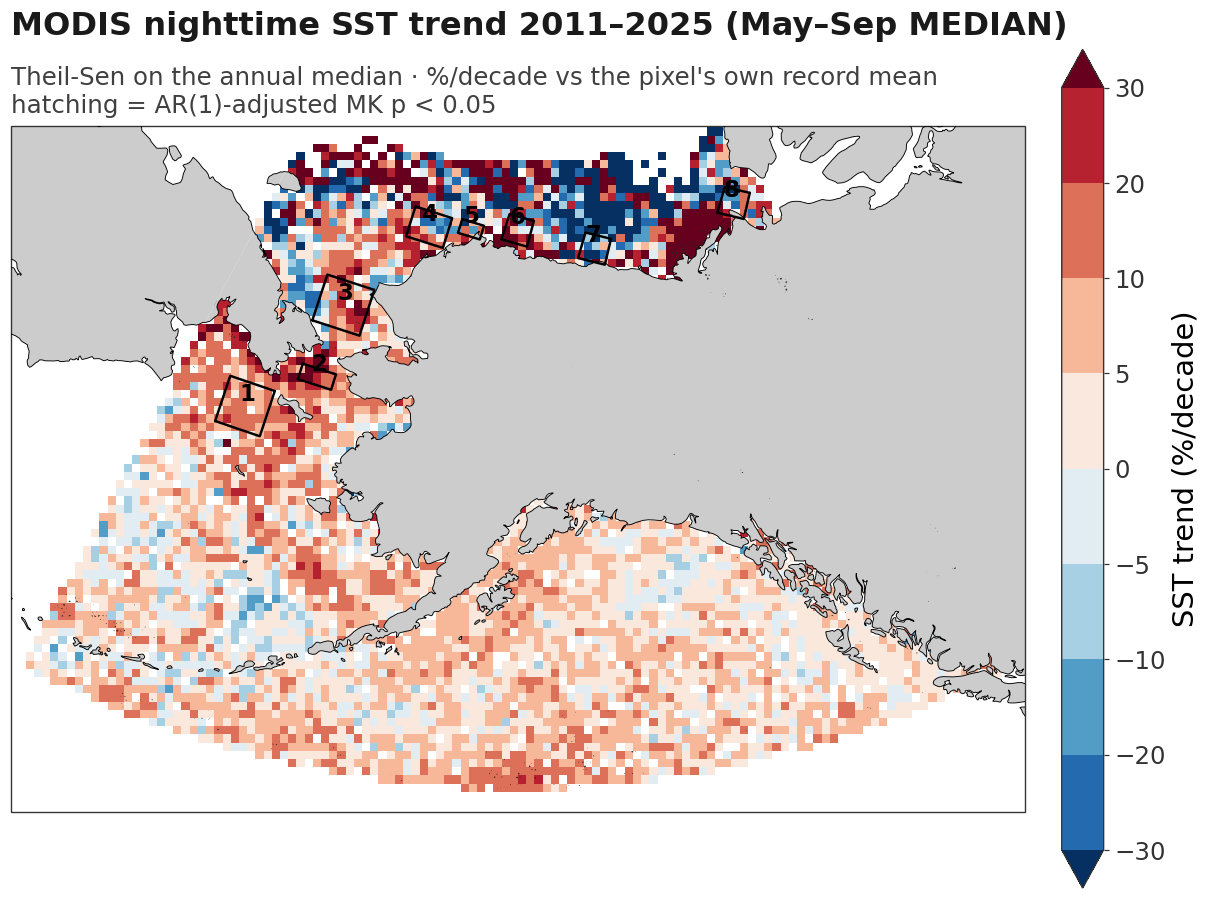

SST trend: median +4.9 %/dec | 76% of fit pixels warming | 2% with p < 0.05


In [24]:
# === FIGURE 7 — MODIS nighttime SST trend, %/decade vs the pixel mean ====================
# Source preference, and why it matters:
#   1. outputs_MODIS_SST/monthly_sst_cache.nc  — monthly means of the DAILY 4 km zarrs, full
#      2002- record. Annual MEDIAN of May-Sep. Reproduces 06_modis-sst-daily.ipynb §18 exactly.
#   2. outputs_MODIS_SST/annual_sst_cache.nc   — same daily-zarr source, already reduced to the
#      annual May-Sep MEAN. Full record, nothing to recompute, but MEAN not MEDIAN (that is §16).
#   3. the outputs_density monthly stack       — LAST RESORT. It starts in 2011 and it was built by
#      nearest-neighbour regridding the monthly L3m lat/lon granules onto EASE-2, which duplicates
#      source cells and is what makes the map look blocky.
_stat, _src = None, None
if p_sst_native is not None and "monthly" in p_sst_native.name:
    _m = xr.open_dataarray(p_sst_native)
    _m = _m.assign_coords(time=pd.to_datetime(_m.time.values))
    grow = _m.sel(time=_m["time.month"].isin(GROW_MONTHS))
    annual_sst = grow.groupby("time.year").median("time")
    _stat, _src = "MEDIAN", p_sst_native.name
elif p_sst_native is not None:
    annual_sst = xr.open_dataarray(p_sst_native)          # already (year, y, x)
    _stat, _src = "MEAN", p_sst_native.name
elif sst_da is not None:
    grow = sst_da.sel(time=sst_da["time.month"].isin(GROW_MONTHS))
    annual_sst = grow.groupby("time.year").median("time")
    _stat, _src = "MEDIAN", p_sst.name
    print("!! falling back to the density SST cache — expect a short record and a blocky map.")
else:
    raise FileNotFoundError(
        "No SST source. Point SST_NATIVE_CACHE at outputs_MODIS_SST/monthly_sst_cache.nc "
        "(preferred) or outputs_MODIS_SST/annual_sst_cache.nc.")

years_sst = annual_sst["year"].values
arr  = annual_sst.values.astype(np.float32)
clim = np.nanmean(arr, axis=0)
assert arr.shape[1:] == dbo_area.shape, f"SST grid {arr.shape[1:]} != {dbo_area.shape}"
print(f"source: {_src} | annual {_stat} of May–Sep | "
      f"{years_sst.min()}–{years_sst.max()} ({len(years_sst)} years)")
if years_sst.min() > 2003:
    print(f"!! record starts {years_sst.min()} — this is NOT the full MODIS Aqua record (2002-07).")

slope_yr, p_adj_med = pixelwise_trend(arr, np.arange(len(years_sst), dtype=float), min_n=8)
slope_pct_med = np.where(np.abs(clim) > 0.1, (slope_yr * 10) / clim * 100, np.nan)

levels = [-30, -20, -10, -5, 0, 5, 10, 20, 30]
cmap   = plt.get_cmap("RdBu_r").copy(); cmap.set_bad("#dddddd", 0.0)
norm_t = mcolors.BoundaryNorm(levels, cmap.N, extend="both")
X, Y   = np.meshgrid(xs, ys)

with plt.rc_context({"hatch.color": "0.15", "hatch.linewidth": 0.8}):
    fig = plt.figure(figsize=(14.5, 11)); ax = plt.axes(projection=disp)
    # no interpolation= here: matplotlib's default 'antialiased' downsamples the 906x845 field
    # smoothly. Forcing 'nearest' is what makes a full-resolution field look pixelated.
    im = ax.imshow(slope_pct_med, origin="upper", extent=[x0, x1, y0, y1], transform=data_crs,
                   norm=norm_t, cmap=cmap, zorder=1)
    sig = np.where(np.isfinite(p_adj_med) & (p_adj_med < P_HATCH), 1.0, np.nan)
    ax.contourf(X, Y, sig, levels=[0.5, 1.5], colors="none", hatches=["....."],
                transform=data_crs, zorder=4)
    base_map(ax); draw_boxes(ax)
    cb = fig.colorbar(im, ax=ax, shrink=0.9, ticks=levels, extend="both", pad=0.03)
    style_cbar(cb, "SST trend (%/decade)")
    map_title(ax, f"MODIS nighttime SST trend {years_sst.min()}–{years_sst.max()} "
                  f"(May–Sep {_stat})",
              f"Theil-Sen on the annual {_stat.lower()} · %/decade vs the pixel's own record mean\n"
              f"hatching = AR(1)-adjusted MK p < {P_HATCH:g}")
    save_fig(fig, "fig7_sst_pct_trend_map")
    plt.show()

_f = np.isfinite(slope_pct_med)
print(f"SST trend: median {np.nanmedian(slope_pct_med):+.1f} %/dec | "
      f"{100*np.nanmean(slope_pct_med[_f] > 0):.0f}% of fit pixels warming | "
      f"{100*np.nanmean(np.isfinite(p_adj_med[_f]) & (p_adj_med[_f] < P_HATCH)):.0f}% with p < {P_HATCH}")

## 9. Per-DBO sea-surface density (σ₀) panels

From `an earlier density notebook (not included)` cell 10. Estimator unchanged (Theil–Sen + AR(1)-corrected
MK on the deseasonalized monthly anomaly); only the type is bigger — axis ticks, axis labels, the box
name, and the per-panel slope/p annotation.

saved -> ~/dbo_figs_redo/fig9_sigma0_box_deseason_trends.png  and  .pdf


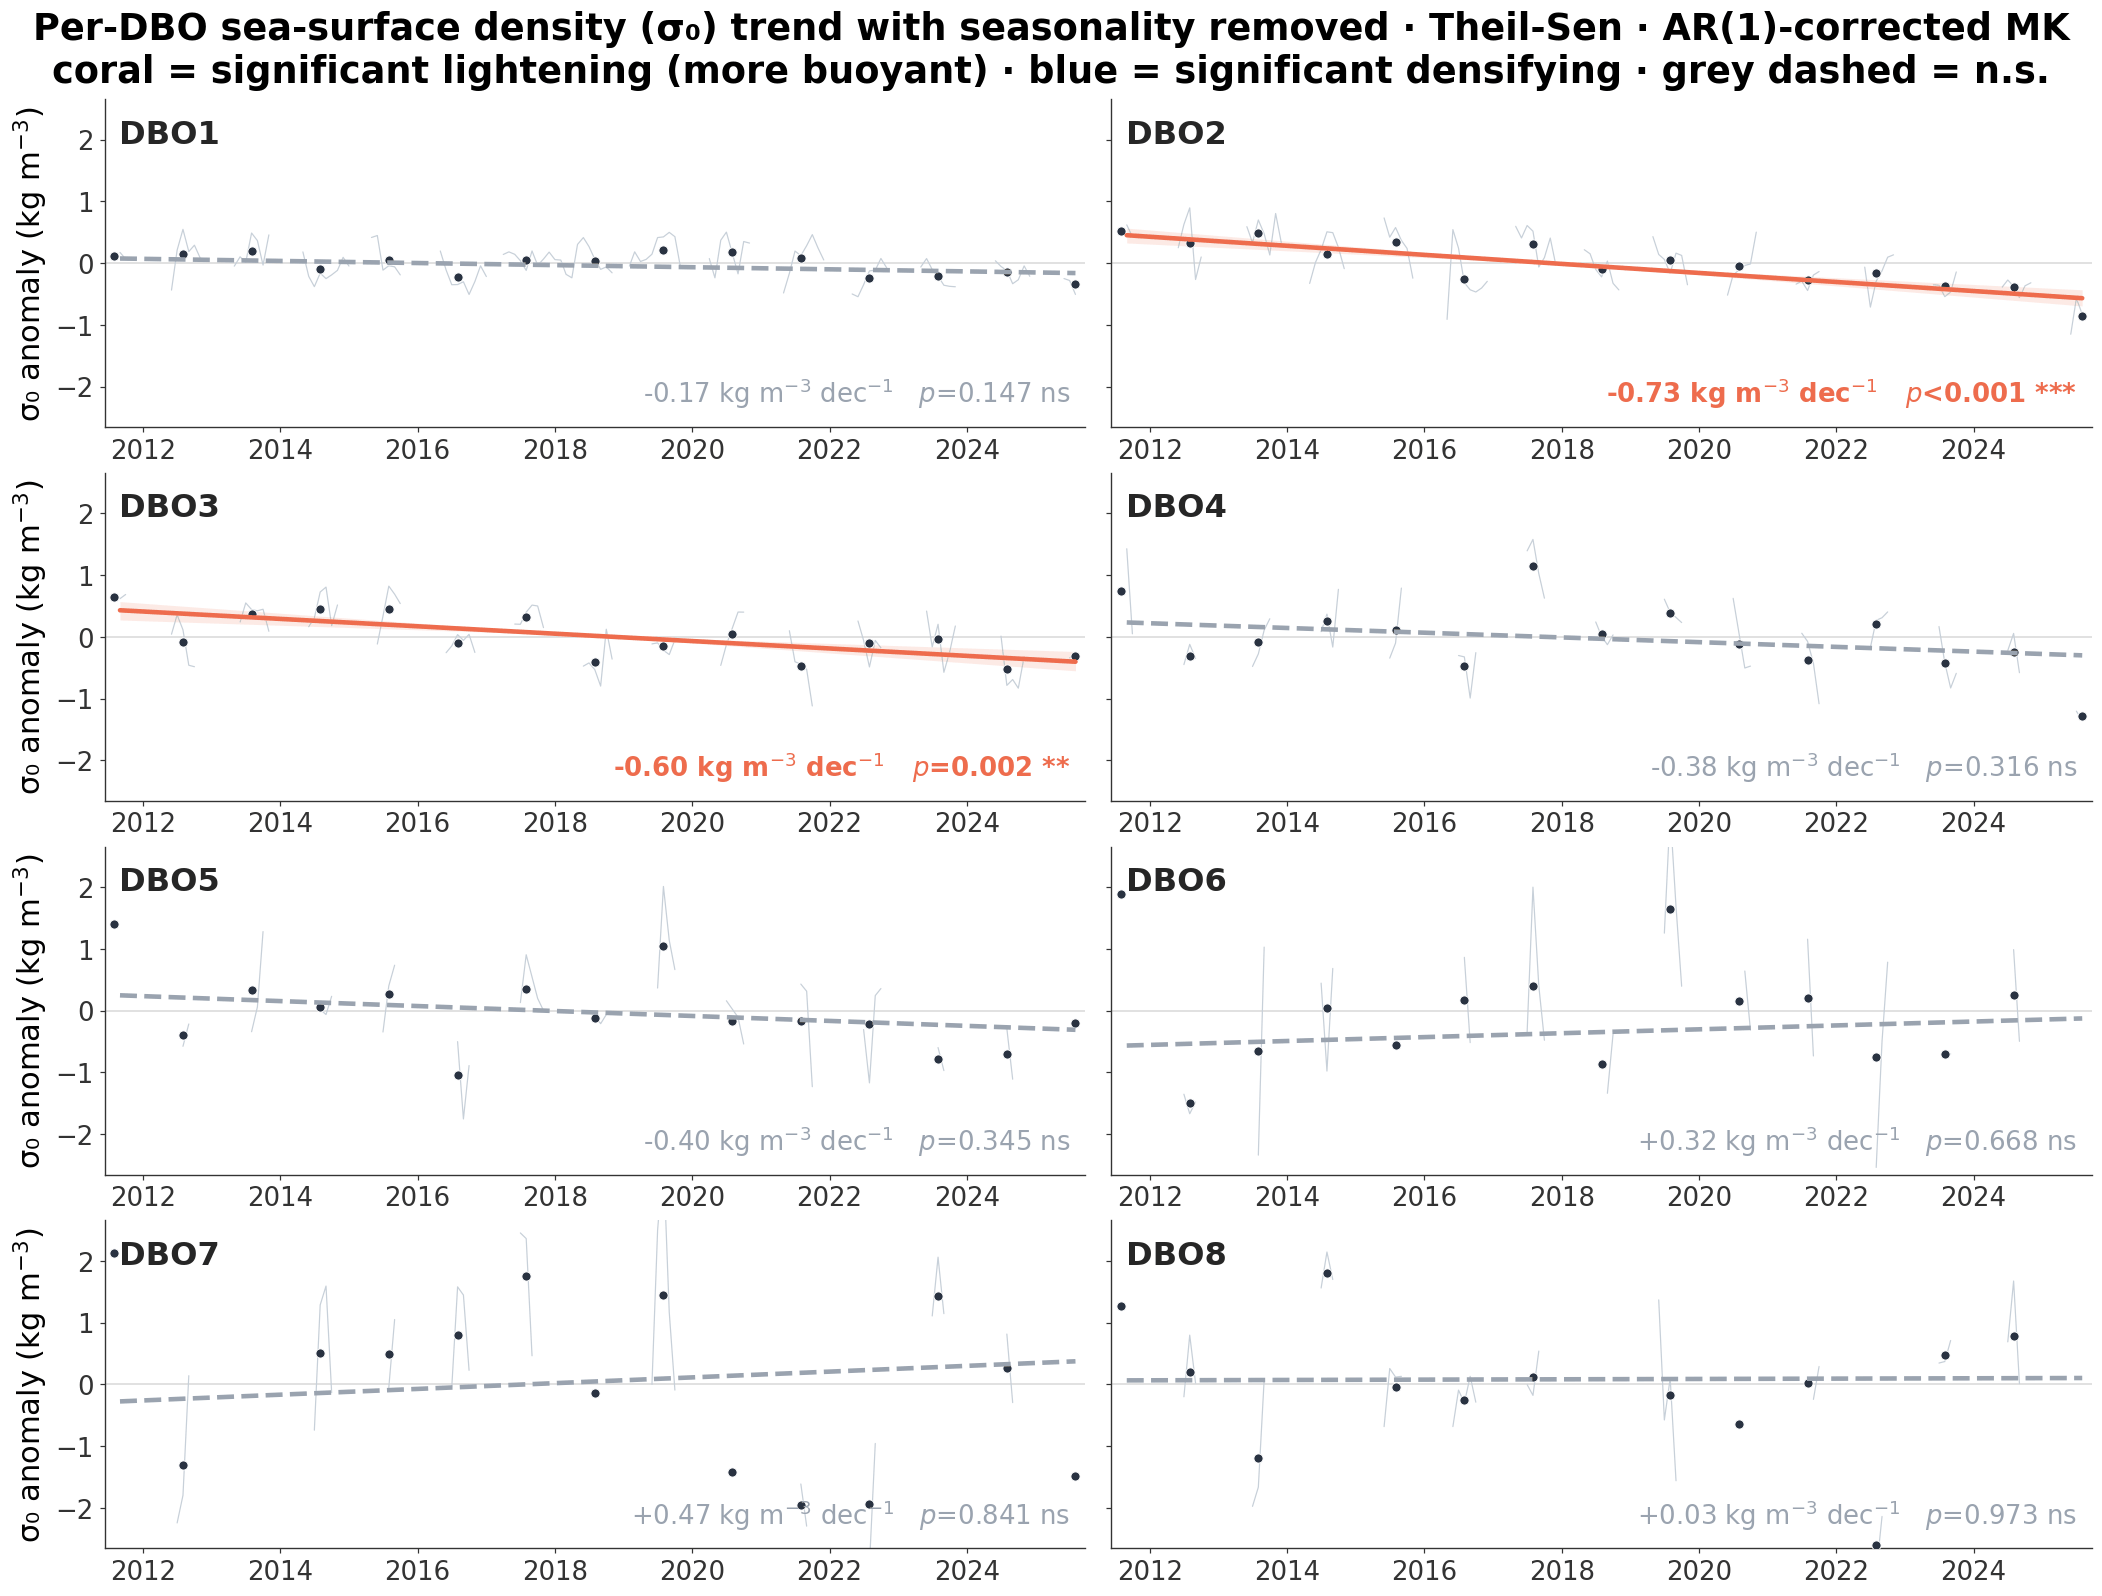

σ₀ trend, kg m⁻³ per decade (2011-09 -> 2025-08):

      sigma0_per_decade  p_MK_AR1  n_months
box                                        
DBO1            -0.1694    0.1468       110
DBO2            -0.7326    0.0000        87
DBO3            -0.5986    0.0023        74
DBO4            -0.3826    0.3160        52
DBO5            -0.4010    0.3451        42
DBO6             0.3152    0.6684        33
DBO7             0.4665    0.8414        37
DBO8             0.0273    0.9733        37


In [26]:
# === FIGURE 9 — per-DBO sigma0 anomaly trends ============================================
if sig0 is None:
    raise FileNotFoundError("σ₀ needs BOTH the SST and SSS monthly caches — see the Part B loader.")

series_d, all_vals = {}, []
for name, mask in box_masks.items():
    d = pd.Series(box_mean(sig0, mask), index=tindex)
    series_d[name] = deseason_pd(d) if d.notna().sum() >= 24 else None
    if series_d[name] is not None:
        all_vals.append(series_d[name].values[np.isfinite(series_d[name].values)])
_yl = np.nanpercentile(np.abs(np.concatenate(all_vals)), 98) * 1.1
YLIM = (-_yl, _yl)

nbx = len(box_masks); ncol = 2; nrow = int(np.ceil(nbx / ncol))
rows8 = []
fig, axes = plt.subplots(nrow, ncol, figsize=(9.5*ncol, 3.6*nrow),
                         sharex=True, sharey=True, squeeze=False, constrained_layout=True)
for ax, (name, mask) in zip(axes.ravel(), box_masks.items()):
    anom = series_d[name]
    if anom is None:
        ax.text(0.5, 0.5, f"{name}\ninsufficient data", ha="center", va="center",
                transform=ax.transAxes, color="0.5", fontsize=FS_PANEL)
        ax.set_xticks([]); ax.set_yticks([])
        for s in ax.spines.values(): s.set_visible(False)
        continue
    v = anom.notna().values
    sl, ic, lo, up = theilslopes(anom.values[v], x_years[v], 0.95)
    p = mk_ar1_p(x_years, anom.values)
    signif = np.isfinite(p) and p < 0.05
    tclr = (LIGHTEN if sl < 0 else DENSIFY) if signif else NS

    ax.axhline(0, color="0.85", lw=1.0, zorder=0)
    ax.plot(tindex, anom.values, lw=0.8, color=RAW, zorder=1)
    yr = anom.groupby(anom.index.year).mean()
    yr_t = pd.to_datetime([f"{y}-08-01" for y in yr.index])
    ax.plot(yr_t, yr.values, "o", ms=6, color=DOT, mec="white", mew=0.6, zorder=3)

    xm, ym = np.median(x_years[v]), np.median(anom.values[v])
    if signif:
        ax.fill_between(tindex, ym + lo*(x_years-xm), ym + up*(x_years-xm),
                        color=tclr, alpha=0.14, lw=0, zorder=2)
    ax.plot(tindex, sl*x_years + ic, lw=3.0, color=tclr, ls="-" if signif else "--", zorder=4)

    ax.text(0.015, 0.94, name, transform=ax.transAxes, fontweight="bold",
            fontsize=FS_PANEL, va="top", color="0.15")
    ax.text(0.985, 0.05, f"{sl*10:+.2f} kg m$^{{-3}}$ dec$^{{-1}}$   {_pmath(p)} {_stars(p)}",
            transform=ax.transAxes, ha="right", va="bottom", fontsize=FS_STAT_P,
            color=tclr, fontweight="bold" if signif else "normal")
    ax.set_ylim(YLIM); ax.xaxis.set_major_locator(mdates.YearLocator(2)); ax.margins(x=0.01)
    ax.tick_params(axis="both", labelsize=FS_TICK_P, labelbottom=True)
    for sp in ("top", "right"): ax.spines[sp].set_visible(False)
    rows8.append((name, sl*10, p, int(anom.notna().sum())))

for ax in axes.ravel()[nbx:]:
    for s in ax.spines.values(): s.set_visible(False)
    ax.set_xticks([]); ax.set_yticks([])
for ax in axes[:, 0]:
    ax.set_ylabel("σ₀ anomaly (kg m$^{-3}$)", fontsize=FS_LAB_P)
fig.suptitle("Per-DBO sea-surface density (σ₀) trend with seasonality removed · Theil-Sen · AR(1)-corrected MK\n"
             "coral = significant lightening (more buoyant) · blue = significant densifying · grey dashed = n.s.",
             fontsize=FS_SUP_P, fontweight="bold")
save_fig(fig, "fig9_sigma0_box_deseason_trends")
plt.show()

tbl8 = pd.DataFrame(rows8, columns=["box", "sigma0_per_decade", "p_MK_AR1", "n_months"]).set_index("box")
pd.set_option("display.float_format", lambda v: f"{v:.4f}")
print(f"σ₀ trend, kg m⁻³ per decade ({tindex[0]:%Y-%m} -> {tindex[-1]:%Y-%m}):\n")
print(tbl8)

---

# Part C — OISSS sea-surface salinity through time  *(self-contained)*

**This section runs on its own.** It re-imports everything, rebuilds the grid, the DBO boxes and the
trend helpers, and reads only `monthly_sss_ease2_oisss_gauss.nc`. You can restart the kernel and run
from the cell below without touching Parts A or B.

Same estimator as every other map in this notebook and as the scorecard: per pixel, monthly value →
month-of-year climatology removed → Theil-Sen slope on the anomaly → **PSU per decade**, with
AR(1)-adjusted Mann-Kendall hatching at p < 0.05 and box outlines coloured by the *box-mean* test.

### Why there is a coverage panel

OISSS is a global product with no latitude cutoff, but its QC discards any retrieval that is
ice-contaminated (ice fraction > 0.0025), in **cold water (SST < 0 °C)**, land-contaminated (land
fraction > 0.01) or taken at wind > 18 m s⁻¹. In the Chukchi and Beaufort that leaves only a short
late-summer window, and the ~40 km footprint fails the land test over much of the narrow shelf where
DBO5–DBO7 sit.

That matters for reading the trend map. DBO4's σ₀ trend is −0.91 kg m⁻³ dec⁻¹ — *larger* than DBO2's
significant −0.77 — yet it reports p = 0.256. Large effect with a weak p is the signature of a short,
gappy record, not of a null. **Panel (b) counts the valid months behind every pixel** so a
non-significant box can be read as "too few observations" rather than "no change", and the printed
table gives the same count per box. Use it before writing any north–south comparison of the salinity
or density rows.

In [13]:
# === PART C, cell 1 of 2 — self-contained setup + load the OISSS monthly stack ============
import warnings, time as _time
from pathlib import Path
import numpy as np, pandas as pd, xarray as xr
import matplotlib as mpl, matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.path import Path as MplPath
import cartopy.crs as ccrs, cartopy.feature as cfeature
from pyresample import AreaDefinition
from scipy.stats import theilslopes, kendalltau, norm
warnings.filterwarnings("ignore")

SSS_CACHE_C = None      # override, e.g. "~/monthly_sss_ease2_oisss_gauss.nc"
STRIDE_C      = 3       # per-pixel fits every STRIDE_C-th pixel (4 km -> 12 km), painted over the block
MIN_MONTHS_C  = 36      # OISSS over the DBO is seasonal; 36 monthly anomalies is already ~9 summers
MIN_YEARS_C   = 8
SIG_C         = 0.05

OUT_C = Path.home() / "dbo_figs_redo"; OUT_C.mkdir(exist_ok=True)  # add your path
mpl.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "figure.facecolor": "white",
    "savefig.bbox": "tight", "savefig.facecolor": "white",
    "font.family": "sans-serif",
    "font.sans-serif": ["Helvetica", "Helvetica Neue", "Arial", "Nimbus Sans", "DejaVu Sans"],
    "axes.linewidth": 0.9, "axes.edgecolor": "0.2",
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
})
FS_T_C, FS_CBL_C, FS_CBT_C, FS_BOX_C = 21, 19, 16, 15
SIG_BOX_C, NS_BOX_C = "#ffd400", "black"

dbo_area_C = AreaDefinition(
    "ease2_north_dbo_4km", "EASE-Grid 2.0 North: Aleutians -> Beaufort (DBO1-8), 4 km", "EPSG:6931",
    {"proj": "laea", "lat_0": 90, "lon_0": 0, "x_0": 0, "y_0": 0, "datum": "WGS84", "units": "m"},
    906, 845, (-3_624_000, 992_000, 0, 4_372_000))
nyC, nxC = dbo_area_C.shape
xsC, ysC = dbo_area_C.get_proj_vectors()
lonC, latC = dbo_area_C.get_lonlats()
xa, ya, xb, yb = dbo_area_C.area_extent
data_crs_C = ccrs.LambertAzimuthalEqualArea(central_latitude=90, central_longitude=0)
disp_C     = ccrs.LambertAzimuthalEqualArea(central_latitude=90, central_longitude=-152)
EXT_C = [-180, -124, 49, 73.5]

DBO_BOXES_C = {
    "DBO1": [(63.769462,-172.312422),(61.945988,-172.186927),(61.846516,-175.790978),(63.662718,-176.147111)],
    "DBO2": [(65.107747,-170.865176),(65.097001,-167.859549),(64.481828,-167.907758),(64.493658,-170.840669)],
    "DBO3": [(66.785880,-171.330008),(68.608869,-171.419334),(68.572412,-166.481029),(66.752281,-166.755808)],
    "DBO4": [(71.994000,-164.226000),(71.801000,-159.729000),(70.641000,-160.305000),(70.821000,-164.556000)],
    "DBO5": [(71.807730,-158.537691),(71.635583,-155.931220),(71.110941,-156.307277),(71.278277,-158.847920)],
    "DBO6": [(71.850000,-150.108000),(70.890000,-150.976000),(71.159000,-153.865000),(72.119000,-152.980000)],
    "DBO7": [(70.868000,-141.528000),(69.946000,-142.679000),(70.333000,-145.439000),(71.253000,-144.256000)],
    "DBO8": [(70.834000,-125.155000),(70.049000,-126.997000),(70.664000,-129.354000),(71.442000,-127.431000)],
}
_pts = np.column_stack([lonC.ravel(), latC.ravel()])
box_masks_C = {n: MplPath([(lo, la) for la, lo in c] + [(c[0][1], c[0][0])])
                     .contains_points(_pts).reshape(lonC.shape)
               for n, c in DBO_BOXES_C.items()}

# ---- find the stack ----
_BASES = [Path("ADD_YOUR_PATH"), Path.home(), Path.cwd(), Path.cwd().parent,  # add your path
          Path.home() / "ADD_YOUR_PATH"]  # add your path
_SUBS  = ["", "outputs_longterm_oisss", "salinity", "salinity/outputs_longterm_oisss",
          "ADD_YOUR_PATH/salinity/outputs_longterm_oisss"]
def _find_sss():
    tried = []
    for b in _BASES:
        for s in _SUBS:
            r = b / s if s else b
            tried.append(r)
            if not r.exists(): continue
            hits = sorted(r.glob("monthly_sss_ease2_oisss_*.nc"))
            if hits: return hits[-1], tried
    return None, tried

if SSS_CACHE_C:
    p_sssC = Path(SSS_CACHE_C)
    if not p_sssC.exists(): raise FileNotFoundError(f"SSS_CACHE_C -> {p_sssC} does not exist")
else:
    p_sssC, _tried = _find_sss()
    if p_sssC is None:
        print("monthly_sss_ease2_oisss_*.nc not found. Searched:")
        for r in dict.fromkeys(_tried): print(f"   {'exists' if r.exists() else '  --  '}  {r}")
        raise FileNotFoundError("set SSS_CACHE_C to the OISSS monthly stack")

_s = xr.open_dataarray(p_sssC)
_s = _s.assign_coords(time=pd.to_datetime(_s.time.values).to_period("M").to_timestamp())
assert (_s.sizes["y"], _s.sizes["x"]) == dbo_area_C.shape, f"SSS grid != {dbo_area_C.shape}"
SSS  = _s.values.astype(np.float32)
WT_C = pd.to_datetime(_s.time.values)
MOY_C, DEC_C = WT_C.month.values, (WT_C.year + (WT_C.month - 0.5) / 12.0).values.astype(float)
_s.close()
print(f"loaded {p_sssC.name} | {len(WT_C)} months {WT_C[0]:%Y-%m} -> {WT_C[-1]:%Y-%m} | "
      f"{100*np.isfinite(SSS).mean():.0f}% of all pixel-months valid")

def _lag1_C(x):
    x = np.asarray(x, float); a, b = x[1:], x[:-1]
    v = np.isfinite(a) & np.isfinite(b)
    return float(np.corrcoef(a[v], b[v])[0, 1]) if v.sum() >= 5 else 0.0

def mk_ar1_C(x, y, minn=MIN_MONTHS_C):
    x = np.asarray(x, float); y = np.asarray(y, float)
    v = np.isfinite(x) & np.isfinite(y); x, y = x[v], y[v]; n = len(x)
    if n < minn: return dict(per_dec=np.nan, p=np.nan, n=n)
    sl, ic, *_ = theilslopes(y, x)
    tau, _ = kendalltau(x, y)
    b1, b0 = np.polyfit(x, y, 1); phi = _lag1_C(y - (b1*x + b0))
    ne = n * (1 - phi) / (1 + phi) if (abs(phi) < 1 and phi != 0) else n
    p = 2*(1 - norm.cdf(abs(tau/np.sqrt(2*(2*ne+5)/(9*ne*(ne-1)))))) if ne > 4 else np.nan
    return dict(per_dec=sl*10, p=p, n=n)

def _stars_C(p):
    return ("***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else "ns") \
        if np.isfinite(p) else "n/a"

def deseason_C(a):
    clim = np.stack([np.nanmean(a[MOY_C == m], axis=0) for m in range(1, 13)])
    return a - clim[MOY_C - 1]

print("Part C setup ready")

loaded monthly_sss_ease2_oisss_gauss.nc | 168 months 2011-09 -> 2025-08 | 31% of all pixel-months valid
Part C setup ready


   fit 30,321/85,164 strided pixels in 1.0 min

box-mean OISSS salinity trend (Theil-Sen on the monthly anomaly):

      PSU/decade  p_AR1  sig  n_months  n_years  mean valid months/pixel
box                                                                     
DBO1      -0.185  0.258   ns       136       15                  116.688
DBO2      -0.791  0.000  ***        99       15                   95.998
DBO3      -0.629  0.009   **        83       15                   79.424
DBO4      -0.494  0.243   ns        78       15                   62.712
DBO5      -0.726  0.207   ns        53       15                   45.057
DBO6       0.219  0.811   ns        41       14                   38.062
DBO7       0.293  0.903   ns        46       15                   44.243
DBO8      -0.476  0.538   ns        53       13                   48.930

Read n_months / n_years BEFORE reading p: a box with a third of the coverage of another
is not being tested at the same power, so 'ns' there may mean 'too

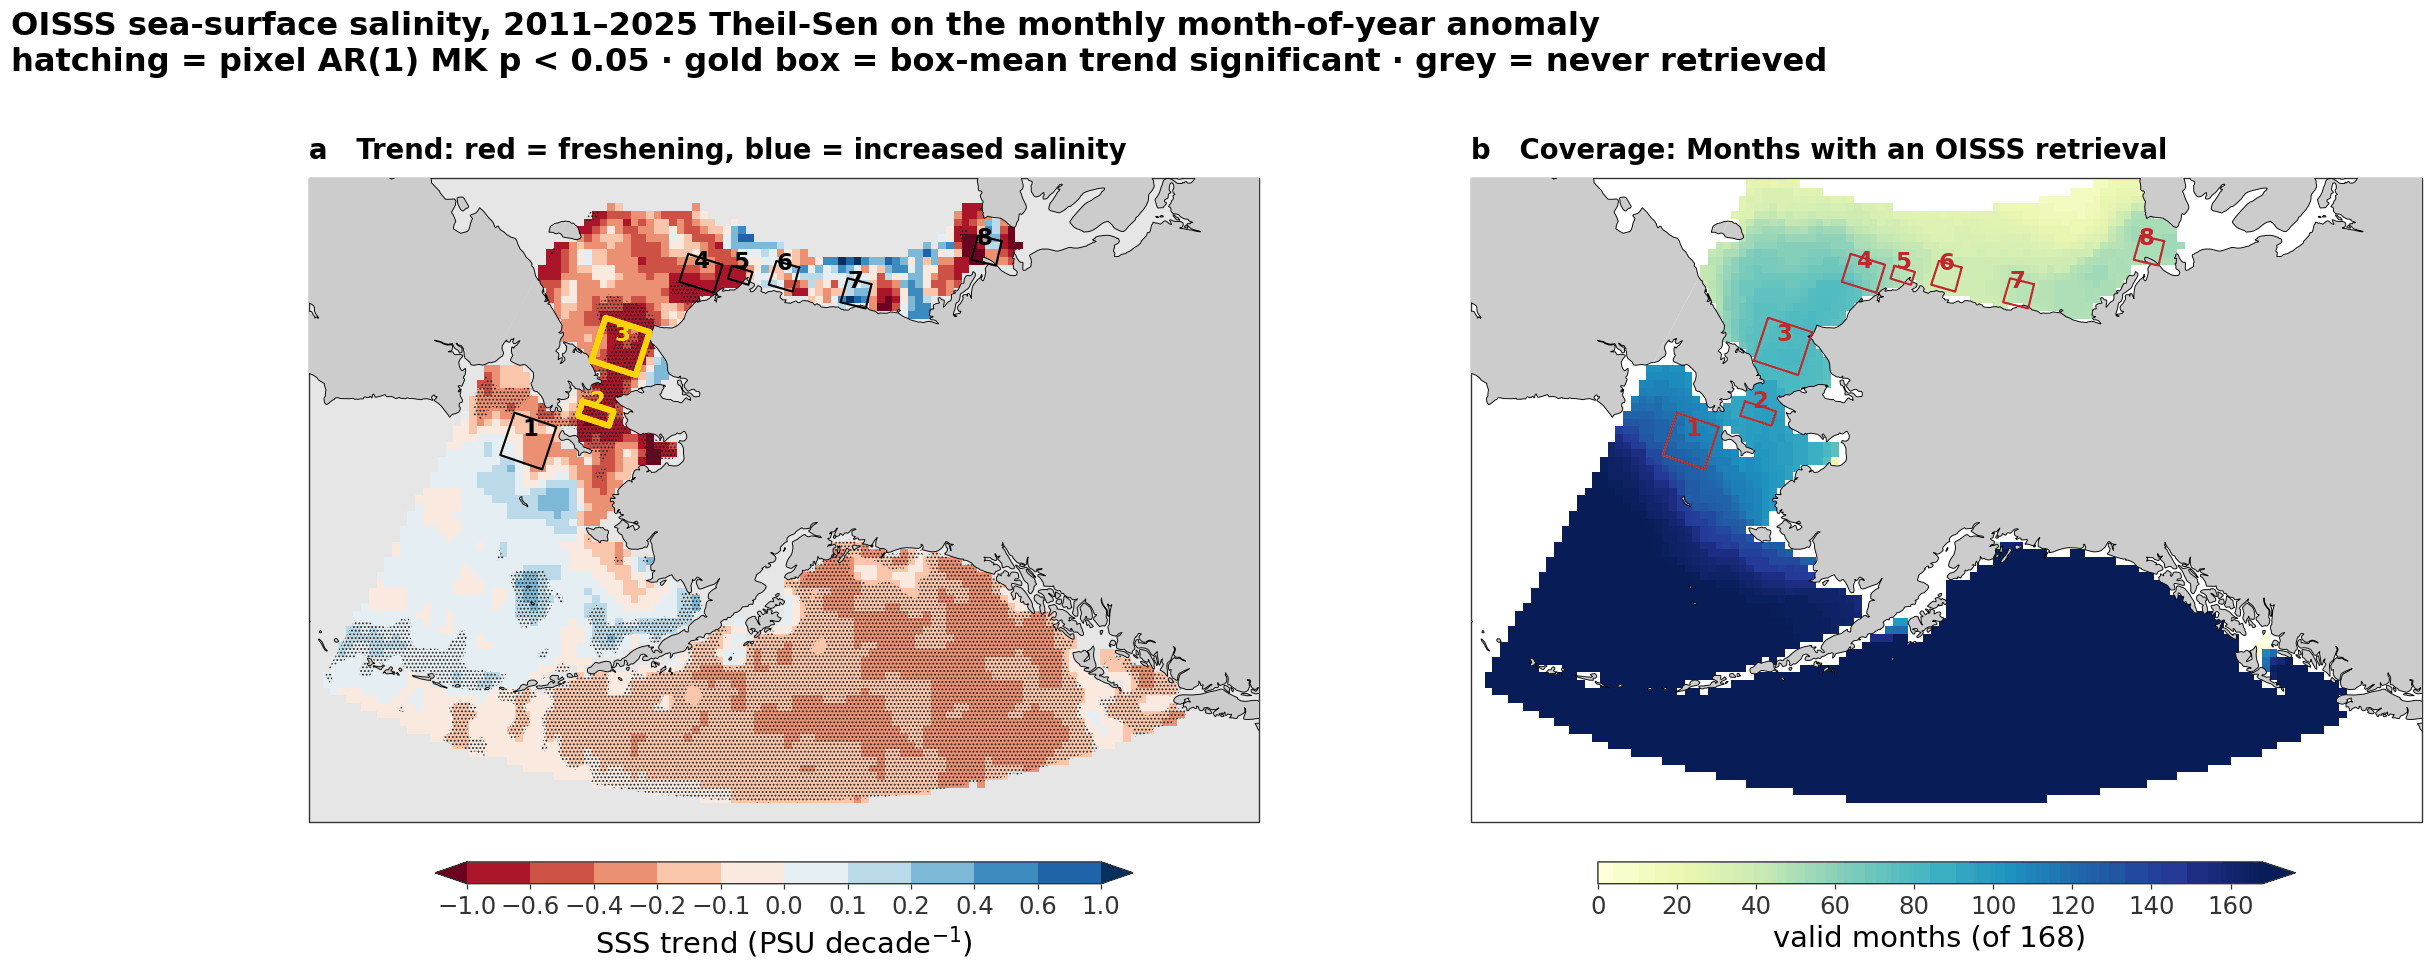

In [14]:
# === PART C, cell 2 of 2 — FIGURE 10: OISSS salinity trend + coverage =====================
S = STRIDE_C
_sub  = SSS[:, ::S, ::S]
_anom = deseason_C(_sub)
_nys, _nxs = _sub.shape[1:]
sss_sl = np.full((_nys, _nxs), np.nan); sss_p = np.full((_nys, _nxs), np.nan)
_t0 = _time.time()
for j in range(_nys):
    for i in range(_nxs):
        a = _anom[:, j, i]; ok = np.isfinite(a)
        if ok.sum() < MIN_MONTHS_C: continue
        if (DEC_C[ok].max() - DEC_C[ok].min()) < MIN_YEARS_C: continue
        r = mk_ar1_C(DEC_C[ok], a[ok])
        sss_sl[j, i] = r["per_dec"]; sss_p[j, i] = r["p"]
    if j % 20 == 0: print(f"   row {j}/{_nys} ({(_time.time()-_t0)/60:.1f} min)", end="\r")
_up = lambda z: np.kron(z, np.ones((S, S)))[:nyC, :nxC]
sss_slope, sss_padj = _up(sss_sl), _up(sss_p)
NVALID = np.isfinite(SSS).sum(axis=0).astype(float)          # full resolution, not strided
print(f"   fit {np.isfinite(sss_sl).sum():,}/{sss_sl.size:,} strided pixels "
      f"in {(_time.time()-_t0)/60:.1f} min")

# ---- box-mean trends, full resolution ----
rows = []
for n, m in box_masks_C.items():
    s = np.nanmean(np.where(m[None, :, :], SSS, np.nan).reshape(len(WT_C), -1), axis=1)
    a = s - np.array([np.nanmean(s[MOY_C == k]) if np.isfinite(s[MOY_C == k]).any() else np.nan
                      for k in range(1, 13)])[MOY_C - 1]
    r = mk_ar1_C(DEC_C, a)
    yrs = len(set(WT_C.year[np.isfinite(a)]))
    rows.append((n, r["per_dec"], r["p"], _stars_C(r["p"]), r["n"], yrs,
                 float(np.nanmean(NVALID[m]))))
tbl_sss = pd.DataFrame(rows, columns=["box", "PSU/decade", "p_AR1", "sig", "n_months",
                                      "n_years", "mean valid months/pixel"]).set_index("box")
pd.set_option("display.float_format", lambda v: f"{v:.3f}")
print("\nbox-mean OISSS salinity trend (Theil-Sen on the monthly anomaly):\n")
print(tbl_sss)
print("\nRead n_months / n_years BEFORE reading p: a box with a third of the coverage of another\n"
      "is not being tested at the same power, so 'ns' there may mean 'too few months'.")
sig_box = {n: (np.isfinite(r["p_AR1"]) and r["p_AR1"] < SIG_C) for n, r in tbl_sss.iterrows()}

def _boxes(ax, sig=None, base="black", fs=FS_BOX_C):
    for name, corners in DBO_BOXES_C.items():
        hot = bool(sig and sig.get(name))
        ring = corners + [corners[0]]
        ax.plot([p[1] for p in ring], [p[0] for p in ring], transform=ccrs.PlateCarree(),
                color=SIG_BOX_C if hot else base, lw=4.0 if hot else 1.4, zorder=9 if hot else 7)
        cla = np.mean([c[0] for c in corners]); clo = np.mean([c[1] for c in corners])
        ax.text(clo, cla + 0.25, name.replace("DBO", ""), transform=ccrs.PlateCarree(),
                color=SIG_BOX_C if hot else base, fontsize=fs, fontweight="bold",
                ha="center", zorder=10)

def _cb(cb, lab):
    cb.set_label(lab, fontsize=FS_CBL_C); cb.ax.tick_params(labelsize=FS_CBT_C)

fig, axes = plt.subplots(1, 2, figsize=(25, 9.5), subplot_kw={"projection": disp_C})

# (a) trend
lv = [-1.0, -0.6, -0.4, -0.2, -0.1, 0, 0.1, 0.2, 0.4, 0.6, 1.0]
cm = plt.get_cmap("RdBu").copy(); cm.set_bad("#e6e6e6", 1.0)
ax = axes[0]
im = ax.imshow(sss_slope, origin="upper", extent=[xa, xb, ya, yb], transform=data_crs_C,
               norm=mcolors.BoundaryNorm(lv, cm.N, extend="both"), cmap=cm,
               interpolation="nearest", zorder=1)
XX, YY = np.meshgrid(xsC, ysC)
with plt.rc_context({"hatch.color": "0.15", "hatch.linewidth": 0.8}):
    ax.contourf(XX, YY, np.where(np.isfinite(sss_padj) & (sss_padj < SIG_C), 1.0, np.nan),
                levels=[0.5, 1.5], colors="none", hatches=["....."],
                transform=data_crs_C, zorder=4)
ax.set_extent(EXT_C, crs=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND, facecolor="0.8", zorder=5); ax.coastlines(lw=0.6, zorder=6)
_boxes(ax, sig=sig_box)
_cb(fig.colorbar(im, ax=ax, shrink=0.72, ticks=lv, extend="both",
                 orientation="horizontal", pad=0.05, aspect=32),
    "SSS trend (PSU decade$^{-1}$)")
ax.text(0.0, 1.02, "a   Trend: red = freshening, blue = increased salinity",
        transform=ax.transAxes, ha="left", va="bottom", fontsize=FS_T_C-3, fontweight="bold")

# (b) coverage — the panel that says whether an 'ns' is a null or just thin data
ax = axes[1]
cov = np.where(NVALID > 0, NVALID, np.nan)
im2 = ax.imshow(cov, origin="upper", extent=[xa, xb, ya, yb], transform=data_crs_C,
                cmap="YlGnBu", vmin=0, vmax=float(np.nanpercentile(cov, 99)),
                interpolation="nearest", zorder=1)
ax.set_extent(EXT_C, crs=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND, facecolor="0.8", zorder=5); ax.coastlines(lw=0.6, zorder=6)
_boxes(ax, base="#c1272d")
_cb(fig.colorbar(im2, ax=ax, shrink=0.72, extend="max",
                 orientation="horizontal", pad=0.05, aspect=32),
    f"valid months (of {len(WT_C)})")
ax.text(0.0, 1.02, "b   Coverage: Months with an OISSS retrieval",
        transform=ax.transAxes, ha="left", va="bottom", fontsize=FS_T_C-3, fontweight="bold")

fig.suptitle(f"OISSS sea-surface salinity, {WT_C[0]:%Y}–{WT_C[-1]:%Y} Theil-Sen on the monthly "
             f"month-of-year anomaly\nhatching = pixel AR(1) MK p < {SIG_C:g} · "
             f"gold box = box-mean trend significant · grey = never retrieved",
             fontsize=FS_T_C, x=0.02, ha="left", fontweight="bold", y=1.04)
for ext in ("png", "pdf"):
    fig.savefig(OUT_C / f"fig10_oisss_sss_trend_coverage.{ext}")
print(f"saved -> {OUT_C/'fig10_oisss_sss_trend_coverage'}.png and .pdf")
plt.show()
tbl_sss.to_csv(OUT_C / "fig10_oisss_sss_box_trends.csv")

---

# Part D — Fig. 6a: sigma0 trend map with yellow significant boxes (uses the Part B loader above)

*This part was a separate notebook before the repository was consolidated; it starts from its own imports and configuration, so it can be run on its own after the sections above.*

In [2]:
# === DBO box masks on the EASE-2 grid (needed by figures 2 and 3) ========================
lons2d, lats2d = dbo_area.get_lonlats()
grid_pts = np.column_stack([lons2d.ravel(), lats2d.ravel()])
box_masks = {name: MplPath([(lo, la) for la, lo in corners] + [(corners[0][1], corners[0][0])])
                        .contains_points(grid_pts).reshape(lons2d.shape)
             for name, corners in DBO_BOXES.items()}
for name, m in box_masks.items():
    print(f"  {name}: {int(m.sum()):>6,} grid cells")

  DBO1:  2,412 grid cells
  DBO2:    605 grid cells
  DBO3:  2,561 grid cells
  DBO4:  1,293 grid cells
  DBO5:    351 grid cells
  DBO6:    739 grid cells
  DBO7:    773 grid cells
  DBO8:    760 grid cells


### Yellow-box helper (the fig-4 wind-speed convention, reusable)

In [7]:

YELLOW = "#ffd400"
def yellow_boxes(ax, boxres, fs=None, ns_color="black", ns_lw=1.4):
    """Box outlines carrying the BOX-MEAN trend: yellow + thick where p < P_HATCH,
    plain otherwise. Same convention as the fig-4 wind-speed map and the chl/bbp/adg maps."""
    for name, corners in DBO_BOXES.items():
        r = None if boxres is None else boxres.get(name)
        hot = (r is not None and np.isfinite(r.get("p", np.nan)) and r["p"] < P_HATCH)
        ring = corners + [corners[0]]
        ax.plot([q[1] for q in ring], [q[0] for q in ring], transform=ccrs.PlateCarree(),
                color=(YELLOW if hot else ns_color), lw=(4.0 if hot else ns_lw),
                zorder=(9 if hot else 5))
        cla = np.mean([c[0] for c in corners]); clo = np.mean([c[1] for c in corners])
        ax.text(clo, cla + 0.25, name.replace("DBO", ""), transform=ccrs.PlateCarree(),
                color=(YELLOW if hot else ns_color), fontsize=(fs or FS_MAP_BOX),
                fontweight="bold", ha="center", zorder=10)
print("yellow_boxes ready")

yellow_boxes ready


## 4. Figure 6: sigma0 trend map with yellow significant boxes

loaded pre-fit σ₀ trend fields from sigma0_trend_map_ease2.nc (2012–2025)

box-mean sigma0 trend (kg m^-3 per decade, monthly anomaly):
      kg m^-3/dec  p_AR1       n  sig
DBO1       -0.169  0.147 110.000   ns
DBO2       -0.733  0.000  87.000  ***
DBO3       -0.599  0.002  74.000   **
DBO4       -0.382  0.316  52.000   ns
DBO5       -0.401  0.345  42.000   ns
DBO6          NaN    NaN  33.000  n/a
DBO7        0.467  0.841  37.000   ns
DBO8        0.027  0.973  37.000   ns
saved -> ~/dbo_figs_redo/fig6_sigma0_trend_map_yellow.png  and  .pdf


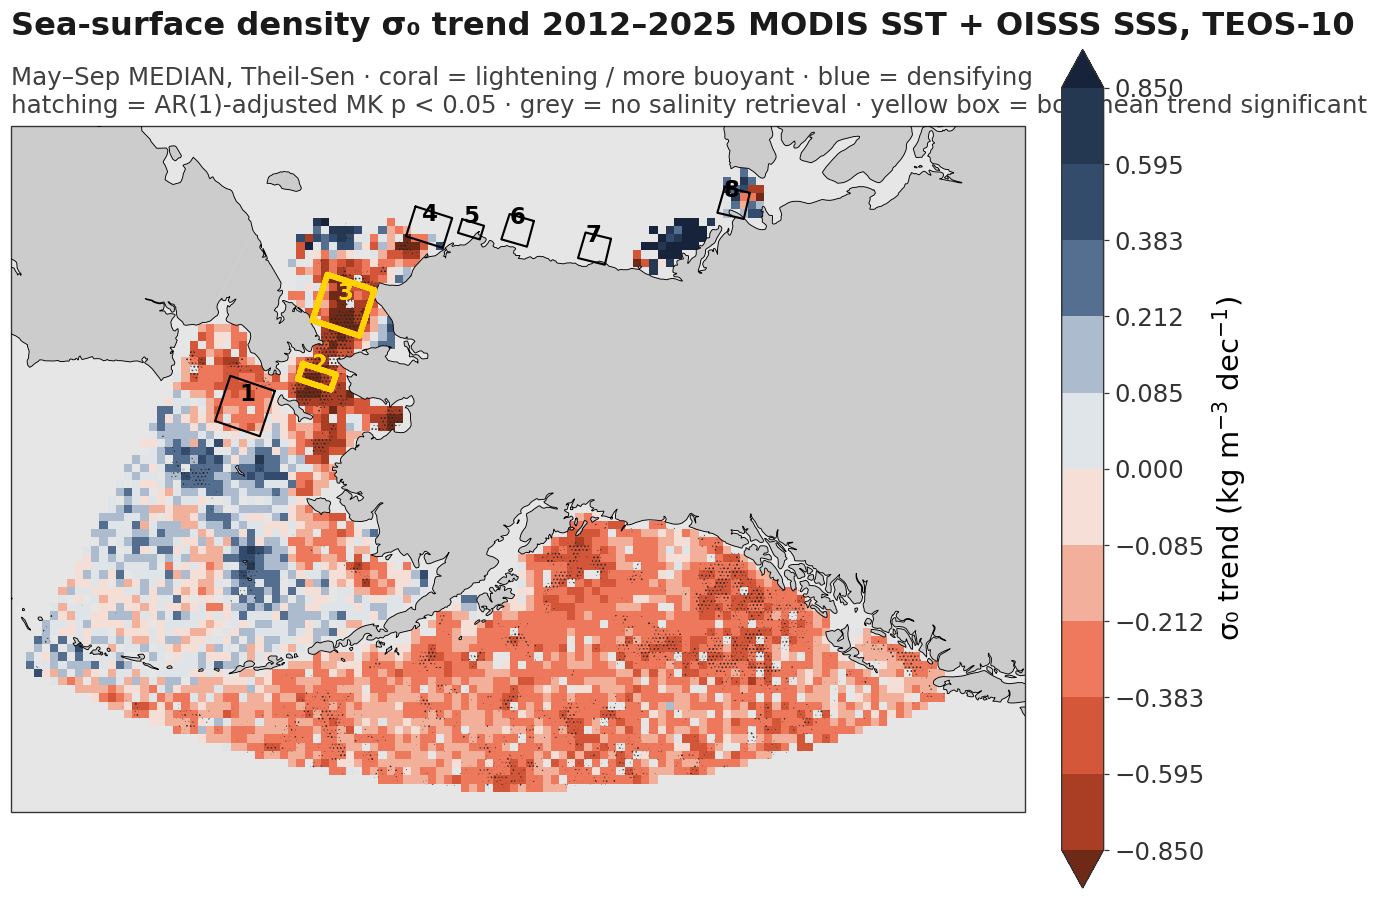

σ₀ trend: median -0.192 kg m⁻³ dec⁻¹ | 77% of fit pixels lightening | 16% with p < 0.05


In [10]:
# === FIGURE 6 — sigma0 trend map, kg m^-3 per decade =====================================
if p_sig is not None:
    _s = xr.open_dataset(p_sig)
    sig_slope, sig_p = _s["sigma0_trend"].values, _s["p_mk_ar1"].values
    import re as _re                        # years live in the free-text "method" attribute
    _m = _re.search(r"(\d{4})\s*-\s*(\d{4})", _s.attrs.get("method", ""))
    sig_years = f"{_m.group(1)}–{_m.group(2)}" if _m else "record"
    print(f"loaded pre-fit σ₀ trend fields from {p_sig.name} ({sig_years})")
elif sig0 is not None:
    sigma_da = xr.DataArray(sig0, dims=("time", "y", "x"), coords={"time": tindex})
    ann_sig  = annual_growing(sigma_da)
    _keepy   = [int(y) for y, k in zip(ann_sig["year"].values,
                                       np.isfinite(ann_sig.values).sum(axis=(1, 2))) if k > 0]
    ann_sig  = ann_sig.sel(year=_keepy)
    _years   = ann_sig["year"].values.astype(float)
    print(f"fitting σ₀ trend: {int(_years.min())}-{int(_years.max())} "
          f"({len(_years)} years, {ANNUAL_STAT} of May–Sep)")
    _sl, sig_p = pixelwise_trend(ann_sig.values, _years, min_n=MIN_YEARS)
    sig_slope  = _sl * 10.0
    sig_years  = f"{int(_years.min())}–{int(_years.max())}"
else:
    raise FileNotFoundError("Need either outputs_density/sigma0_trend_map_ease2.nc, or both the "
                            "SST and SSS monthly caches.")

# --- box-mean sigma0 trend (deseasonalized monthly anomaly, Theil-Sen + AR(1) MK) ------
#     the same estimator as the sigma0 panels (fig 9) and the scorecard row
sig_boxres = None
if sig0 is not None:
    _dec = np.asarray(tindex.year + (tindex.month - 0.5) / 12.0, float)
    sig_boxres = {}
    for n, m in box_masks.items():
        s = pd.Series(box_mean(sig0, m), index=tindex)
        a = deseason_pd(s).values; ok = np.isfinite(a)
        r = mk_ar1(_dec[ok], a[ok], minn=36)
        sig_boxres[n] = dict(per_dec=r["per_dec"], p=r["p_adj"], n=int(ok.sum()))
    _t6 = pd.DataFrame(sig_boxres).T
    _t6["sig"] = [_stars(p) for p in _t6["p"]]
    print("\nbox-mean sigma0 trend (kg m^-3 per decade, monthly anomaly):")
    print(_t6.rename(columns={"per_dec": "kg m^-3/dec", "p": "p_AR1"}).round(4))
else:
    print("!! SST+SSS caches unavailable - sigma0 box test skipped, boxes drawn plain")

def sigma_cmap():
    c = mcolors.LinearSegmentedColormap.from_list(
        "sigma_trend", ["#6E2A16", "#C1462A", LIGHTEN, "#F3B9A6", "#F7F7F5",
                        "#B6C4D5", DENSIFY, "#2A3F5A", "#16233A"]).copy()
    c.set_bad("#e6e6e6", 1.0)
    return c

def sym_levels(field, pct=98, nsteps=(1.0, 0.7, 0.45, 0.25, 0.1)):
    """Symmetric 'nice' contour levels bracketing the bulk of the field."""
    a = np.nanpercentile(np.abs(field), pct)
    mag = 10.0 ** np.floor(np.log10(a)); vmx = np.ceil(a / mag * 2) / 2 * mag
    fr = np.array(nsteps)
    return np.round(np.concatenate([-vmx * fr, [0.0], vmx * fr[::-1]]), 4), vmx

levels, _vmax = sym_levels(sig_slope)
cmap  = sigma_cmap(); tnorm = mcolors.BoundaryNorm(levels, cmap.N, extend="both")
X, Y  = np.meshgrid(xs, ys)
sig_hatch = np.where(np.isfinite(sig_p) & (sig_p < P_HATCH), 1.0, np.nan)

with plt.rc_context({"hatch.color": "0.15", "hatch.linewidth": 0.8}):
    fig = plt.figure(figsize=(14.5, 11)); ax = plt.axes(projection=disp)
    im = ax.imshow(sig_slope, origin="upper", extent=[x0, x1, y0, y1], transform=data_crs,
                   norm=tnorm, cmap=cmap, interpolation="nearest", zorder=1)
    ax.contourf(X, Y, sig_hatch, levels=[0.5, 1.5], colors="none", hatches=["....."],
                transform=data_crs, zorder=4)
    base_map(ax); yellow_boxes(ax, sig_boxres)
    cb = fig.colorbar(im, ax=ax, shrink=0.9, ticks=levels, extend="both", pad=0.03)
    style_cbar(cb, "σ₀ trend (kg m$^{-3}$ dec$^{-1}$)")
    map_title(ax, f"Sea-surface density σ₀ trend {sig_years} MODIS SST + OISSS SSS, TEOS-10",
              f"May–Sep {ANNUAL_STAT.upper()}, Theil-Sen · coral = lightening / more buoyant · "
              f"blue = densifying\nhatching = AR(1)-adjusted MK p < {P_HATCH:g} · "
              f"grey = no salinity retrieval · yellow box = box-mean trend significant")
    save_fig(fig, "fig6_sigma0_trend_map_yellow")
    plt.show()

_f = np.isfinite(sig_slope)
print(f"σ₀ trend: median {np.nanmedian(sig_slope):+.3f} kg m⁻³ dec⁻¹ | "
      f"{100*np.nanmean(sig_slope[_f] < 0):.0f}% of fit pixels lightening | "
      f"{100*np.nanmean(np.isfinite(sig_p[_f]) & (sig_p[_f] < P_HATCH)):.0f}% with p < {P_HATCH}")